# Exploratory Data Analysis (EDA)

In this section, we will explore the Heart Disease dataset to understand its structure, features, and target variable. We will examine descriptive statistics, identify missing values, duplicates, and potential outliers, and visualize feature distributions and relationships.

The findings will guide data cleaning, preprocessing, and feature engineering decisions, establishing a reliable foundation for model training and evaluation.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, pointbiserialr, mannwhitneyu

# Define column names
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num", 
    "marital-status", "occupation", "relationship", "race", 
    "sex", "capital-gain", "capital-loss", "hours-per-week", 
    "native-country", "income"
]

# Load original training dataset
df_train = pd.read_csv(
    "../data/raw/adult.data",
    header=None,
    names=columns,
    skipinitialspace=True,
    na_values="?"
)

# Load original test dataset
df_test = pd.read_csv(
    "../data/raw/adult.test",
    header=None,
    names=columns,
    skiprows=1,  # Skip metadata line
    skipinitialspace=True,
    na_values="?"
)

# Standardize target labels - for some reason there is a "." at the end of string
df_test["income"] = df_test["income"].str.rstrip(".")

# Inspect dataset structure
print("\nDatasets Shapes")
print(f"Shape: {df_train.shape}")
print(f"Shape: {df_test.shape}")

# Combine datasets - we will analyze the data as one and split later
df = pd.concat(
    [df_train, df_test],
    ignore_index=True
)

print(f"\nFull Dataset Shape: {df.shape}")

print("=" * 50)

print("\nFull Data Head")
display(df.head())

print("=" * 50)
print("\nData Info")
df.info()




Datasets Shapes
Shape: (32561, 15)
Shape: (16281, 15)

Full Dataset Shape: (48842, 15)

Full Data Head


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



Data Info
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       46043 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      46033 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  47985 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.3 MB


### Initial Dataset Inspection

The Adult Income dataset contains **48,842 observations and 15 columns**, consisting of 14 input features and one target variable (`income`).

The dataset includes **6 numerical and 8 categorical features**, covering demographic, educational, employment, and financial characteristics. The target variable represents a binary classification problem: predicting whether an individual's annual income exceeds $50,000.

The initial inspection confirms that the dataset was loaded successfully and that the feature types are generally appropriate. Some categorical columns contain null values, which will be examined during the data quality assessment.

#### Feature Descriptions

| Feature | Type | Description |
|---|---|---|
| `age` | Numerical | Age of the individual in years |
| `workclass` | Categorical | Employment sector or type of employer |
| `fnlwgt` | Numerical | Census sampling weight representing population estimates |
| `education` | Categorical | Highest level of education attained |
| `education-num` | Numerical (ordinal) | Education level encoded as an ordered integer |
| `marital-status` | Categorical | Marital status of the individual |
| `occupation` | Categorical | Type of occupation or job |
| `relationship` | Categorical | Relationship status within the household |
| `race` | Categorical | Recorded racial category |
| `sex` | Categorical | Recorded sex category |
| `capital-gain` | Numerical | Reported capital gains |
| `capital-loss` | Numerical | Reported capital losses |
| `hours-per-week` | Numerical | Number of hours worked per week |
| `native-country` | Categorical | Country of origin |
| **`income`** | **Binary target** | Whether annual income is `<=50K` or `>50K` |

**Initial observations:**

- `education` and `education-num` represent the same underlying information in different formats, introducing potential redundancy.
- `fnlwgt` is a census sampling weight rather than a direct socioeconomic measurement.
- `capital-gain` and `capital-loss` are numerical financial variables that may have highly skewed distributions.
- `income` is the classification target, while the remaining 14 columns are candidate predictors.

These characteristics will be examined further during exploratory analysis and feature selection.

In [2]:
# ============================================================
# Data Quality Assessment
# ============================================================

# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Calculate missing-value statistics
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
})

print(missing[missing["Missing Count"] > 0])

# Inspect categorical features
categorical_cols = df.select_dtypes(include=["object", "str", "category"]).columns

print("\nCategorical feature cardinality:")
print(df[categorical_cols].nunique().sort_values(ascending=False))

Duplicate rows: 52
                Missing Count  Missing (%)
workclass                2799         5.73
occupation               2809         5.75
native-country            857         1.75

Categorical feature cardinality:
native-country    41
education         16
occupation        14
workclass          8
marital-status     7
relationship       6
race               5
sex                2
income             2
dtype: int64


### Data Quality Assessment

The initial data quality assessment identified the following:

**1. Duplicate Records**

- **52 duplicate rows** (0.11% of the dataset).
- These records require further investigation before removal, since identical demographic and employment characteristics may belong to different individuals.

**2. Missing Values**

| Feature | Missing Count | Missing (%) |
|---|---:|---:|
| `workclass` | 2,799 | 5.73% |
| `occupation` | 2,809 | 5.75% |
| `native-country` | 857 | 1.75% |

Missing values are limited to three categorical features. Since the proportions are relatively low, categorical imputation using the most frequent category or a dedicated `"Unknown"` category may be appropriate. The final strategy will be evaluated during preprocessing.

**3. Categorical Cardinality**

The categorical features range from 2 to 41 unique values.

- **High cardinality:** `native-country` (41 categories).
- **Moderate cardinality:** `education` (16), `occupation` (14).
- **Low cardinality:** The remaining categorical features (2–8 categories).

These differences will influence the choice of encoding techniques, particularly for `native-country`.

**Conclusion**

The dataset is suitable for further analysis. The main preprocessing considerations are handling missing categorical values, investigating duplicate records, and selecting appropriate encoding strategies. All transformations will be implemented in reproducible pipelines to prevent data leakage.

In [3]:
# ============================================================
# Duplicate Investigation
# ============================================================

# Extract all rows belonging to duplicate groups
duplicates = df[df.duplicated(keep=False)]

print(f"Duplicate rows (excluding first occurrences): {df.duplicated().sum()}")
print(f"Total rows involved in duplicate groups: {len(duplicates)}")

# Display most frequently repeated records
display(
    df.value_counts(dropna=False)
      .loc[lambda x: x > 1]
      .head(10)
)

# Compare duplicate distribution across income classes
display(
    df.loc[df.duplicated(), "income"]
      .value_counts()
)

Duplicate rows (excluding first occurrences): 52
Total rows involved in duplicate groups: 101


age  workclass  fnlwgt  education     education-num  marital-status      occupation         relationship   race                sex     capital-gain  capital-loss  hours-per-week  native-country  income
25   Private    308144  Bachelors     13             Never-married       Craft-repair       Not-in-family  White               Male    0             0             40              Mexico          <=50K     3
                195994  1st-4th       2              Never-married       Priv-house-serv    Not-in-family  White               Female  0             0             40              Guatemala       <=50K     3
21   Private    243368  Preschool     1              Never-married       Farming-fishing    Not-in-family  White               Male    0             0             50              Mexico          <=50K     3
39   Private    184659  HS-grad       9              Married-civ-spouse  Machine-op-inspct  Husband        White               Male    0             0             40            

income
<=50K    46
>50K      6
Name: count, dtype: int64

#### Duplicate Investigation

The dataset contains **52 duplicate occurrences (0.11%)**, with 101 observations belonging to 49 distinct duplicate groups. Most repeated records appear twice, while three appear three times.

The majority of additional duplicate occurrences belong to the `<=50K` income class (46 of 52).

Because the dataset lacks unique individual identifiers, identical feature values do not necessarily indicate duplicated individuals. These observations may represent different people sharing the same recorded characteristics.

**Decision:** Retain all observations at this stage, as there is insufficient evidence to classify the duplicates as data errors. Potential overlap between training and test sets will be considered during data splitting.

In [4]:
# ============================================================
# Missing Value Investigation
# ============================================================

missing_cols = ["workclass", "occupation", "native-country"]

# Number of rows containing at least one missing value
print(
    "Rows with missing values:",
    df[missing_cols].isna().any(axis=1).sum()
)

# Analyze combinations of missing values
missing_patterns = (
    df[missing_cols]
    .isna()
    .value_counts()
    .rename("count")
    .reset_index()
    .sort_values("count", ascending=False)
)

print("\n*** Missing Patterns ***")
print(missing_patterns)

# ============================================================
# Missingness vs. Income
# ============================================================

print("\nMissingness vs. Income")
for col in missing_cols:
    print(f"\nMissingness analysis: {col}")

    # Income distribution conditional on missingness
    print(
        pd.crosstab(
            df[col].isna(),
            df["income"],
            normalize="index"
        ).round(3)
    )

Rows with missing values: 3620

*** Missing Patterns ***
   workclass  occupation  native-country  count
0      False       False           False  45222
1       True        True           False   2753
2      False       False            True    811
3       True        True            True     46
4      False        True           False     10

Missingness vs. Income

Missingness analysis: workclass
income     <=50K   >50K
workclass              
False      0.752  0.248
True       0.905  0.095

Missingness analysis: occupation
income      <=50K   >50K
occupation              
False       0.752  0.248
True        0.906  0.094

Missingness analysis: native-country
income          <=50K   >50K
native-country              
False           0.761  0.239
True            0.743  0.257


#### Missing-Value Investigation

The dataset contains **3,620 observations (7.41%) with at least one missing value**, while 45,222 observations (92.59%) are complete.

Missing values are concentrated in three categorical features: `workclass`, `occupation`, and `native-country`.

**Key findings:**

- **Strong missingness overlap:** All 2,799 observations with missing `workclass` also have missing `occupation`, suggesting a relationship between their missing-data patterns.
- **Association with income:** Only approximately 9.5% of observations with missing employment information belong to the `>50K` income class, compared with approximately 24.8% among observations with recorded employment information.
- **Native-country missingness:** Income distributions are relatively similar between observations with and without recorded `native-country` values.

**Preprocessing recommendation:**

Retain observations with missing values and initially impute missing categorical entries using a dedicated `"Unknown"` category. This preserves potentially useful missingness information without introducing assumptions about the original values.

The imputation strategy will be implemented and evaluated within the preprocessing pipeline after data splitting to prevent leakage.

**Conclusion:** Missing employment information appears to contain predictive information and should not be discarded without further evaluation.


### Univariate Analysis

Univariate analysis examines each feature independently to understand its distribution, central tendency, variability, and potential anomalies.

We will analyze numerical features using descriptive statistics, histograms, and boxplots, followed by categorical frequency distributions and target class balance.

The findings will help identify skewed distributions, extreme values, rare categories, and potential preprocessing requirements for the machine learning pipeline.

#### Numerical Features

We begin by examining the numerical features to understand their statistical properties and identify potential outliers or unusual distributions.

In [5]:
# ============================================================
# Numerical Feature Analysis - Descriptive Statistics
# ============================================================

# Select numerical features
num_cols = df.select_dtypes(include="number").columns.tolist()

# Calculate descriptive statistics
num_stats = df[num_cols].describe().T

# Add skewness
num_stats["skewness"] = df[num_cols].skew()

# Display results
display(num_stats.round(2))

,count,mean,std,min,25%,50%,75%,max,skewness
age,48842.0,38.64,13.71,17.0,28.0,37.0,48.0,90.0,0.56
fnlwgt,48842.0,189664.13,105604.03,12285.0,117550.5,178144.5,237642.0,1490400.0,1.44
education-num,48842.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0,-0.32
capital-gain,48842.0,1079.07,7452.02,0.0,0.0,0.0,0.0,99999.0,11.89
capital-loss,48842.0,87.50,403.00,0.0,0.0,0.0,0.0,4356.0,4.57
hours-per-week,48842.0,40.42,12.39,1.0,40.0,40.0,45.0,99.0,0.24


#### Numerical Descriptive Statistics — Findings

The descriptive statistics reveal considerable differences in the distributions of the six numerical features.

- **Age:** Moderately right-skewed (0.56), with a mean of 38.64 years and a median of 37.
- **Final weight (`fnlwgt`):** Right-skewed (1.44), with substantial variability in census sampling weights.
- **Education level (`education-num`):** Slightly left-skewed (-0.32), with a median of 10. This feature represents ordinal educational attainment rather than a continuous measurement.
- **Capital gain:** Extremely right-skewed (11.89), with at least 75% of observations equal to zero and a maximum of 99,999.
- **Capital loss:** Strongly right-skewed (4.57), with at least 75% of observations equal to zero.
- **Hours per week:** Slightly right-skewed (0.24), with a median of 40 hours and a maximum of 99.

**Conclusion:** The financial features exhibit substantial zero inflation and positive skewness, making them candidates for further investigation and possible transformation. The remaining numerical features show more moderate asymmetry.

No transformations will be applied during EDA. Preprocessing decisions will be evaluated later within the training pipeline.

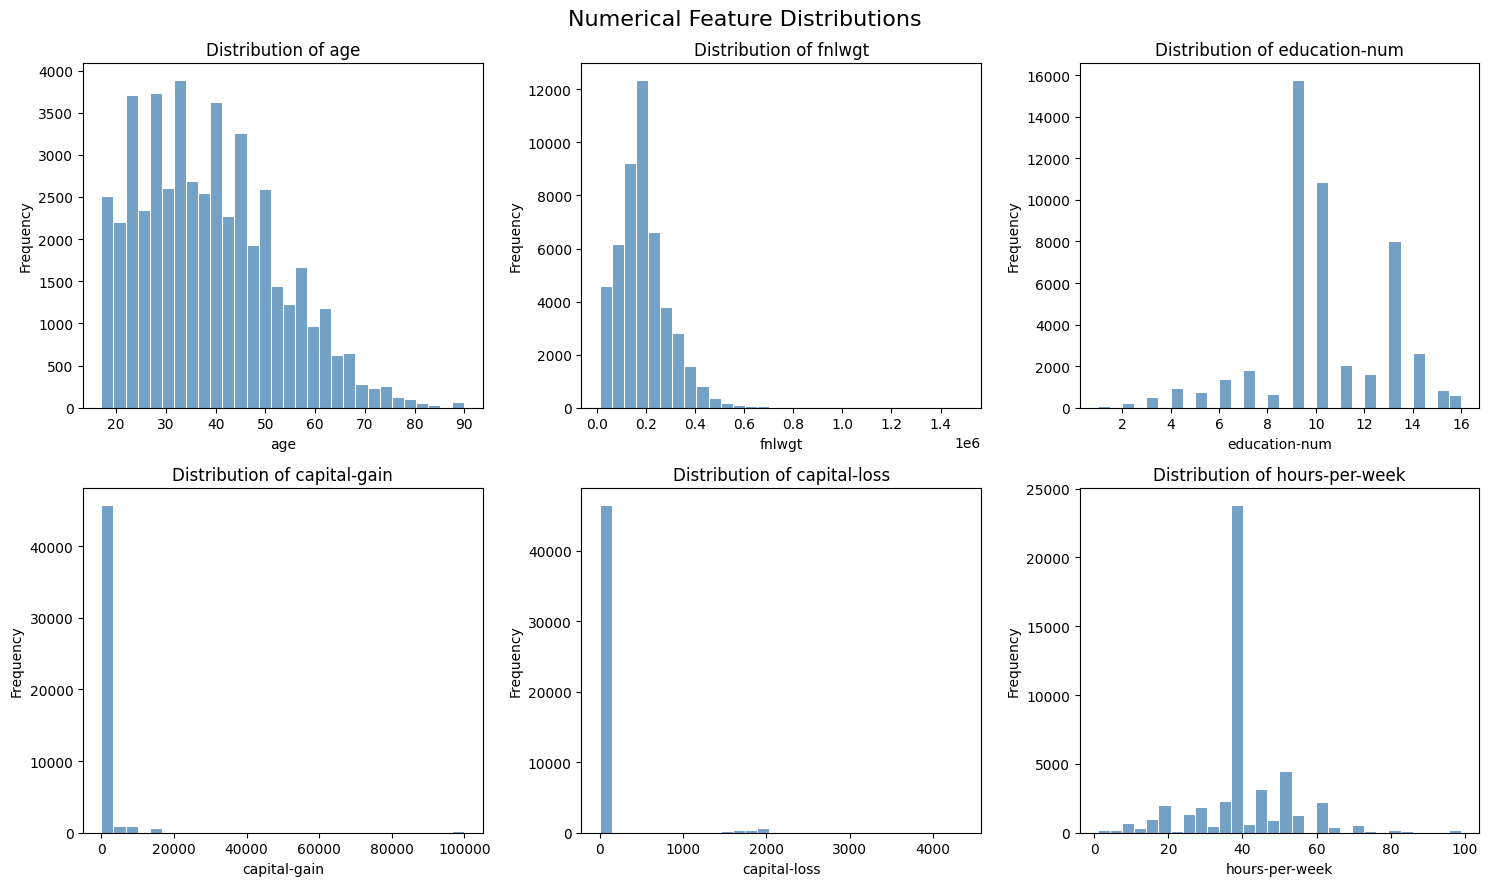

In [6]:
# ============================================================
# Numerical Feature Distributions - Histograms
# ============================================================


# Create a 2x3 grid of histograms
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, col in zip(axes.flat, num_cols):
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        color="steelblue",
        edgecolor="white",
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.suptitle("Numerical Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

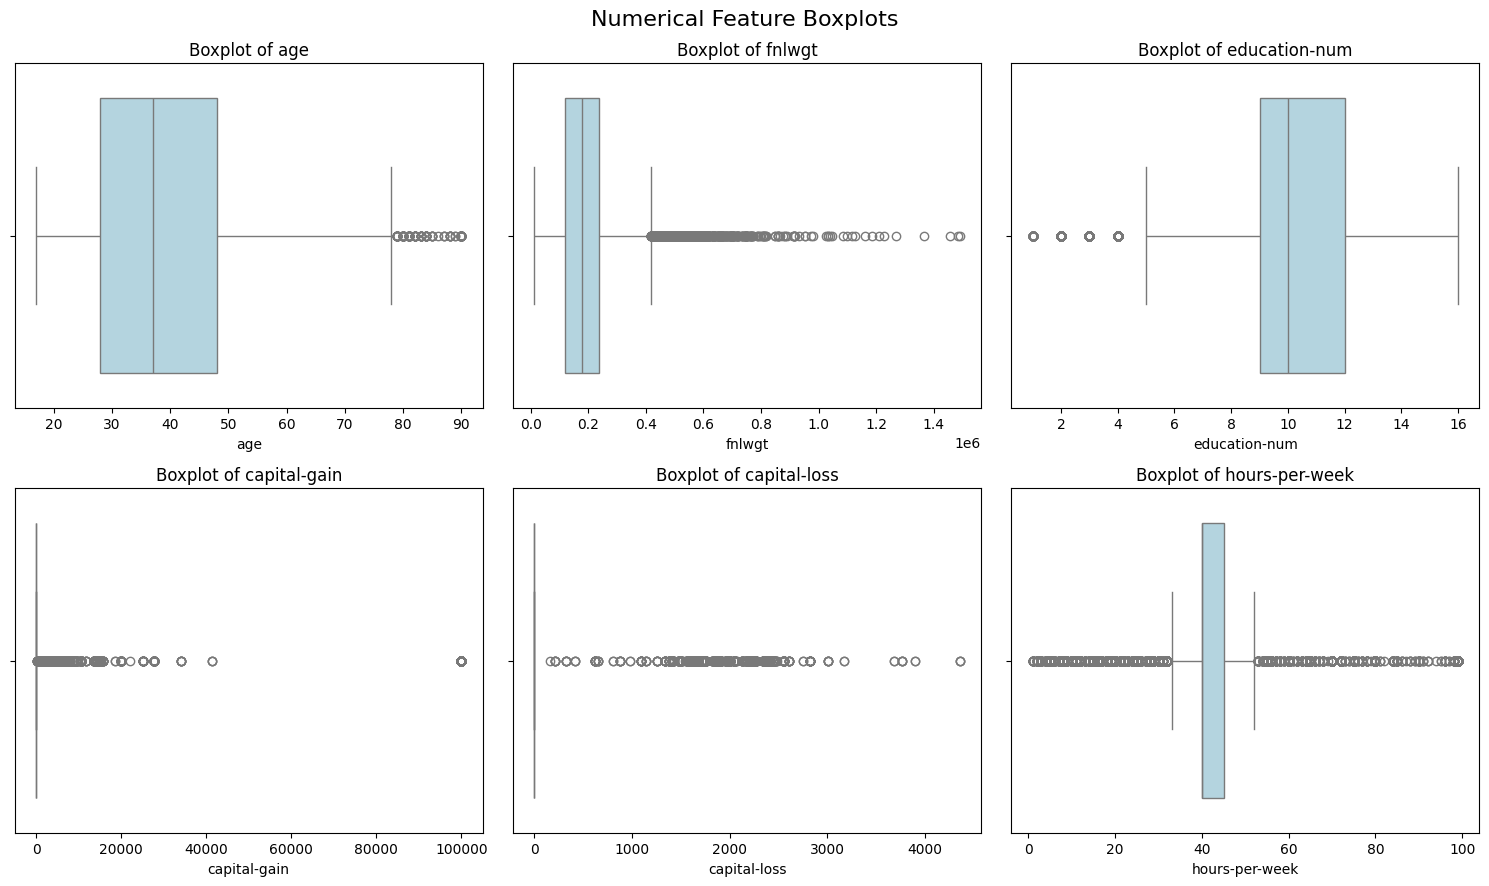

In [7]:
# ============================================================
# Numerical Feature Distributions - Boxplots
# ============================================================

# Create a 2x3 grid of boxplots
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(
        data=df,
        x=col,
        color="lightblue",
        ax=ax
    )

    ax.set_title(f"Boxplot of {col}")
    ax.set_xlabel(col)

plt.suptitle("Numerical Feature Boxplots", fontsize=16)
plt.tight_layout()
plt.show()

### Numerical Feature Distributions — Histograms and Boxplots: Findings

The histograms and boxplots reveal differences in the distributions, variability, and presence of extreme values across the six numerical features.

| Feature | Distribution and Outlier Analysis |
|---|---|
| `age` | Moderately right-skewed (0.56), with most observations concentrated among younger and middle-aged adults. Values above approximately 78 years are flagged as outliers but remain plausible. |
| `fnlwgt` | Right-skewed (1.44), with a long upper tail and numerous high-value outliers. These represent census sampling weights and require careful interpretation. |
| `education-num` | Slightly left-skewed (-0.32), with distinct peaks corresponding to educational attainment levels. Low values are flagged as outliers but represent valid ordinal categories. |
| `capital-gain` | Extremely right-skewed (11.89), with most observations equal to zero. The boxplot collapses at zero, causing all positive values to be flagged as outliers. |
| `capital-loss` | Strongly right-skewed (4.57), with a similar concentration at zero. Conventional IQR-based outlier detection is unsuitable for this distribution. |
| `hours-per-week` | Slightly right-skewed (0.24), with a prominent concentration at 40 hours. Values below approximately 33 and above 53 hours are flagged as outliers, potentially representing legitimate working schedules. |

#### Key Findings

1. **Skewness:** Financial features exhibit the strongest positive skewness, followed by `fnlwgt`. Age and working hours have more moderate asymmetry.
2. **Zero-heavy distributions:** `capital-gain` and `capital-loss` have an interquartile range of zero, making conventional boxplots and IQR-based outlier detection less informative.
3. **Potential outliers:** Extreme values appear across several features, but none can be classified as erroneous based solely on the visualizations.
4. **Feature characteristics:** `education-num` represents ordinal information, while `fnlwgt` is a census sampling weight rather than a conventional numerical measurement.

#### Conclusions and Preprocessing Considerations

- **Outlier handling:** Retain all observations at this stage. Investigate extreme values before considering removal or capping.
- **Financial features:** Examine nonzero values separately and consider testing transformations such as `log1p` or binary indicators for positive gains and losses.
- **Feature selection:** Evaluate whether `fnlwgt` should be included as a predictor and avoid redundant representations of education.
- **Scaling:** Assess numerical scaling requirements according to the machine learning algorithms selected.

**Overall conclusion:** The numerical features exhibit substantial differences in distribution, particularly the highly skewed and zero-heavy financial variables. These findings will guide preprocessing decisions, but transformations will be implemented and evaluated later using training data to avoid data leakage.

### Categorical Feature Analysis

This section examines the distribution of categorical features to identify dominant categories, class imbalances, rare values, and potential data inconsistencies.

We will use frequency tables and count plots to understand how observations are distributed across categories. These findings will inform categorical encoding and preprocessing decisions during model development.

In [8]:
# ============================================================
# Categorical Feature Analysis - Descriptive Statistics
# ============================================================

# Select categorical predictors (exclude target)
cat_cols = df.select_dtypes(
    include=["object", "str", "category"]
).columns.drop("income").tolist()

# Summarize categorical features
cat_stats = df[cat_cols].describe().T

# Add missing-value percentages
cat_stats["missing_pct"] = (
    df[cat_cols].isna().mean() * 100
).round(2)

display(cat_stats)

,count,unique,top,freq,missing_pct
workclass,46043,8,Private,33906,5.73
education,48842,16,HS-grad,15784,0.00
marital-status,48842,7,Married-civ-spouse,22379,0.00
occupation,46033,14,Prof-specialty,6172,5.75
relationship,48842,6,Husband,19716,0.00
race,48842,5,White,41762,0.00
sex,48842,2,Male,32650,0.00
native-country,47985,41,United-States,43832,1.75


In [9]:
# ============================================================
# Categorical Feature Analysis - Frequency Tables
# ============================================================

for col in cat_cols:
    print(f"\n{'=' * 50}")
    print(f"Feature: {col}")
    print(f"{'=' * 50}")

    freq = pd.DataFrame({
        "count": df[col].value_counts(dropna=False),
        "percentage": (
            df[col].value_counts(normalize=True, dropna=False) * 100
        ).round(2)
    })

    display(freq)


Feature: workclass


,count,percentage
workclass,,
Private,33906,69.42
Self-emp-not-inc,3862,7.91
Local-gov,3136,6.42
NaN,2799,5.73
State-gov,1981,4.06
Self-emp-inc,1695,3.47
Federal-gov,1432,2.93
Without-pay,21,0.04
Never-worked,10,0.02



Feature: education


,count,percentage
education,,
HS-grad,15784,32.32
Some-college,10878,22.27
Bachelors,8025,16.43
Masters,2657,5.44
Assoc-voc,2061,4.22
11th,1812,3.71
Assoc-acdm,1601,3.28
10th,1389,2.84
7th-8th,955,1.96



Feature: marital-status


,count,percentage
marital-status,,
Married-civ-spouse,22379,45.82
Never-married,16117,33.00
Divorced,6633,13.58
Separated,1530,3.13
Widowed,1518,3.11
Married-spouse-absent,628,1.29
Married-AF-spouse,37,0.08


... (6 outputs left out)


Feature: sex


,count,percentage
sex,,
Male,32650,66.85
Female,16192,33.15



Feature: native-country


,count,percentage
native-country,,
United-States,43832,89.74
Mexico,951,1.95
NaN,857,1.75
Philippines,295,0.60
Germany,206,0.42
Puerto-Rico,184,0.38
Canada,182,0.37
El-Salvador,155,0.32
India,151,0.31


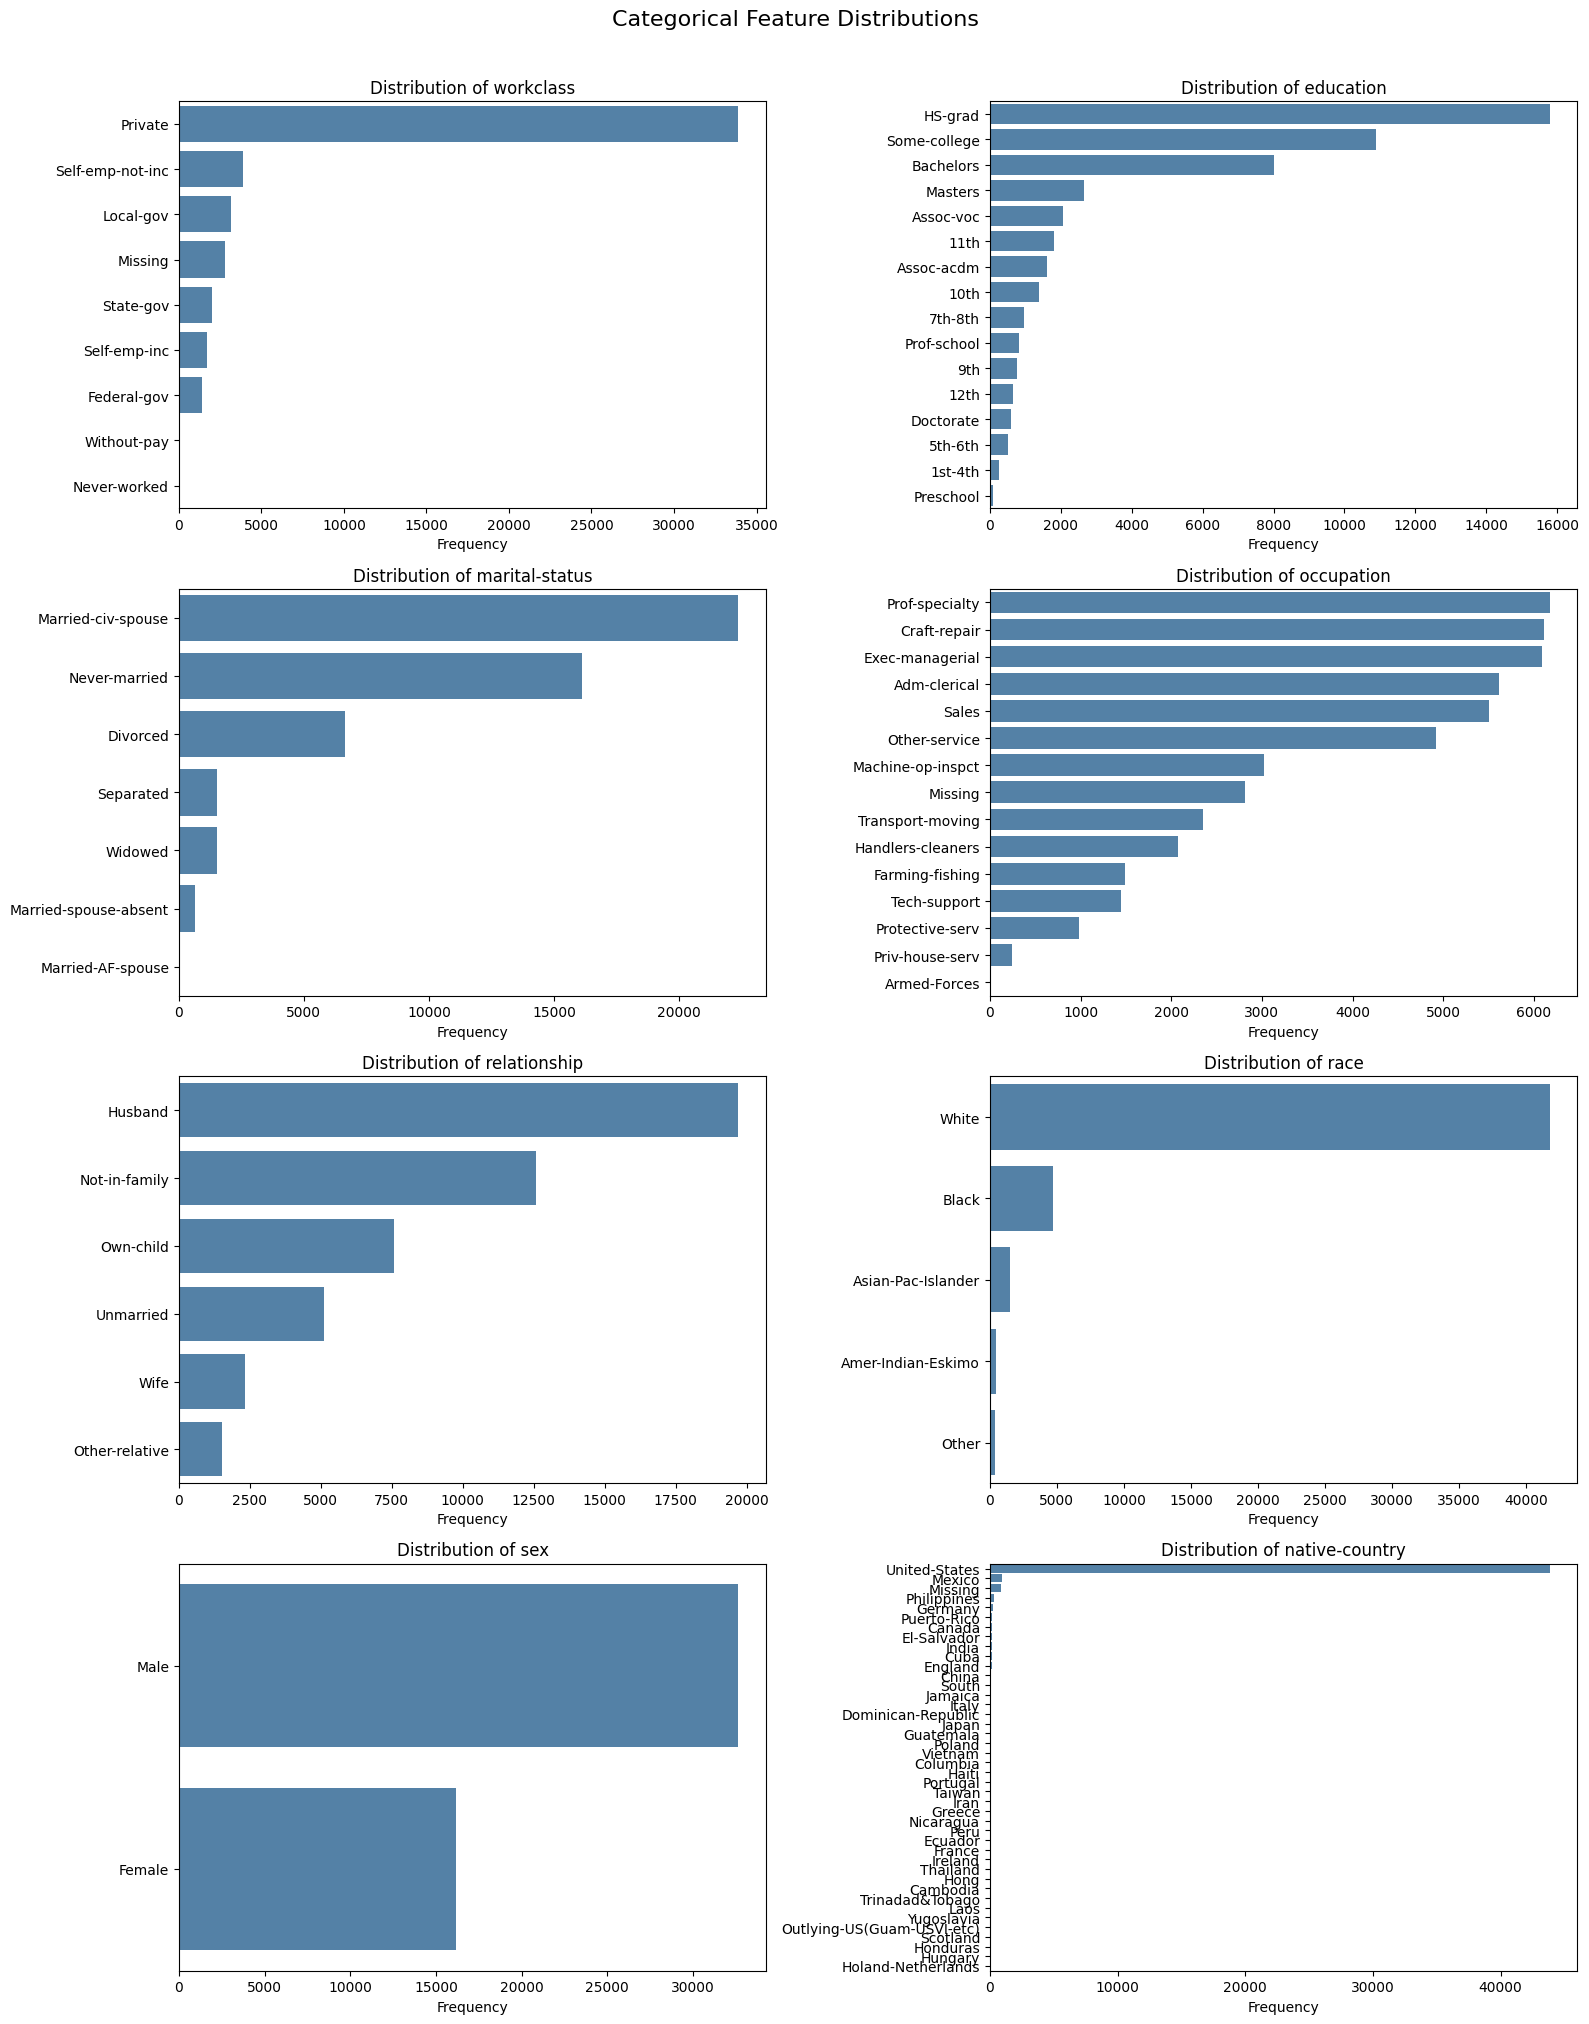

In [10]:
# ============================================================
# Categorical Feature Analysis - Count Plots
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(4, 2, figsize=(16, 20))

for ax, col in zip(axes.flat, cat_cols):

    # Include missing values as a separate category for visualization
    counts = df[col].fillna("Missing").value_counts()

    sns.barplot(
        x=counts.values,
        y=counts.index,
        color="steelblue",
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Frequency")
    ax.set_ylabel("")

plt.suptitle(
    "Categorical Feature Distributions",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

### Categorical Feature Distributions — Findings

The categorical feature distributions reveal substantial differences in category frequencies, with several features dominated by a small number of categories. Some features also contain rare categories that may require special consideration during preprocessing.

#### Feature Analysis

| Feature | Distribution and Observations |
|---|---|
| `workclass` | **Private-sector employment** dominates the distribution, representing approximately 70% of observations. Self-employment and government employment account for smaller proportions, while `Without-pay` and `Never-worked` are extremely rare. Missing values form a noticeable group. |
| `education` | `HS-grad` is the most frequent category, followed by `Some-college` and `Bachelors`. Advanced degrees and lower educational attainment categories are less common. The distribution is concentrated around a few education levels. |
| `marital-status` | `Married-civ-spouse` and `Never-married` account for most observations, followed by `Divorced`. Other marital statuses are considerably less frequent. |
| `occupation` | The distribution is relatively diverse. `Prof-specialty`, `Craft-repair`, and `Exec-managerial` are among the most frequent occupations. `Armed-Forces` and `Priv-house-serv` are rare categories. Missing values are also present. |
| `relationship` | `Husband` is the most frequent category, followed by `Not-in-family` and `Own-child`. `Other-relative` and `Wife` are less represented. |
| `race` | `White` overwhelmingly dominates the dataset, followed by `Black`. Other racial categories have substantially fewer observations, indicating a pronounced demographic imbalance. |
| `sex` | The dataset contains considerably more male than female observations, with males representing approximately two-thirds of the sample. |
| `native-country` | `United-States` accounts for the vast majority of observations. The remaining 40 countries are individually much less frequent, producing a highly imbalanced, high-cardinality feature. |

#### Key Findings

**1. Dominant Categories and Imbalance**

Several categorical features exhibit substantial concentration in particular categories, especially `workclass`, `race`, `sex`, and `native-country`.

This indicates that the dataset is not evenly distributed across demographic and employment groups. Such imbalances may affect model generalization and should be considered when evaluating performance across different populations.

**2. Rare Categories**

Features such as `occupation`, `workclass`, and `native-country` contain categories with very few observations.

Rare categories may produce unstable estimates or sparse encoded features, particularly when using one-hot encoding. Grouping infrequent categories may be worth evaluating during preprocessing.

**3. High Cardinality**

`native-country` has the highest cardinality, with 41 distinct categories. Its distribution is heavily dominated by `United-States`, while most other countries contribute relatively few observations.

This feature may benefit from rare-category grouping or alternative encoding strategies. However, no grouping decisions should be made without evaluating their effect on model performance.

**4. Potential Feature Redundancy**

The categorical variable `education` and numerical variable `education-num` encode the same underlying educational attainment information.

Additionally, `marital-status` and `relationship` may contain overlapping information. Their relationships will be investigated during multivariate analysis.

**5. Missing Categories**

Missing values in `workclass`, `occupation`, and `native-country` were previously identified during the data quality assessment. Their appearance in the frequency plots confirms that missingness represents a meaningful proportion of certain feature distributions.

#### Conclusions and Preprocessing Considerations

- **Categorical encoding:** One-hot encoding is a reasonable initial approach for nominal categorical features.
- **Rare categories:** Consider grouping infrequent categories, particularly within `native-country` and `occupation`, if justified by model evaluation.
- **Missing values:** Preserve missingness information using the previously proposed `"Unknown"` imputation strategy as an initial experiment.
- **Feature redundancy:** Evaluate whether both representations of education are necessary.
- **Demographic imbalance:** Examine model performance across demographic groups to identify potential differences in predictive reliability.
- **Data validation:** Preserve and validate the expected categorical values to ensure consistency between training and production inference.

**Overall conclusion:** The categorical features exhibit substantial frequency imbalances, varying cardinality, and several rare categories. These characteristics will influence encoding, feature selection, and model evaluation. No categorical transformations will be applied during EDA; preprocessing strategies will be implemented and evaluated later within the training pipeline.

### Target Variable Analysis

The target variable, `income`, represents a binary classification problem with two categories:

- `<=50K`: Annual income of $50,000 or less.
- `>50K`: Annual income exceeding $50,000.

We will examine the frequency and proportion of each class to identify potential imbalance and determine appropriate strategies for model training and evaluation.

In [11]:
# ============================================================
# Target Variable Analysis - Class Distribution
# ============================================================

target = "income"

# Calculate class frequencies and percentages
target_dist = pd.DataFrame({
    "count": df[target].value_counts(),
    "percentage": (
        df[target].value_counts(normalize=True) * 100
    ).round()
})

display(target_dist)

# Calculate majority-to-minority class ratio
class_counts = df[target].value_counts()

imbalance_ratio = class_counts.max() / class_counts.min()

print(f"Class imbalance ratio: {imbalance_ratio:.2f}:1")

,count,percentage
income,,
<=50K,37155,76.0
>50K,11687,24.0


Class imbalance ratio: 3.18:1


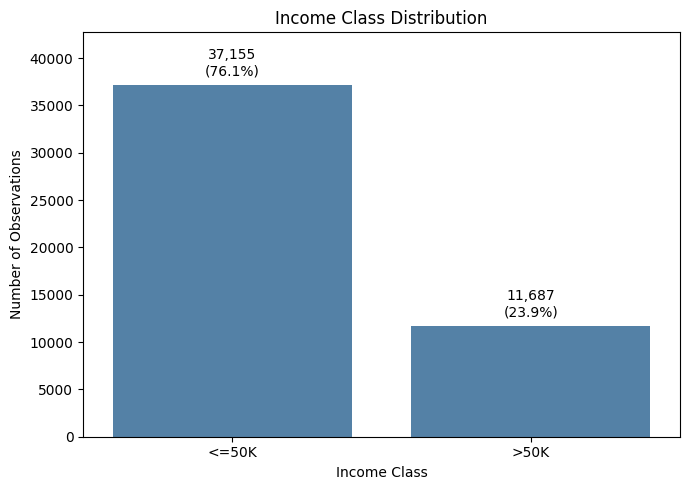

In [12]:
# ============================================================
# Target Variable Analysis - Visualization
# ============================================================

fig, ax = plt.subplots(figsize=(7, 5))

# Plot class frequencies
sns.countplot(
    data=df,
    x="income",
    order=["<=50K", ">50K"],
    color="steelblue",
    ax=ax
)

# Add percentage labels
total = len(df)

for bar in ax.patches:
    count = bar.get_height()
    percentage = count / total * 100

    ax.annotate(
        f"{count:,.0f}\n({percentage:.1f}%)",
        (bar.get_x() + bar.get_width() / 2, count),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

ax.set_title("Income Class Distribution")
ax.set_xlabel("Income Class")
ax.set_ylabel("Number of Observations")
ax.set_ylim(0, class_counts.max() * 1.15)

plt.tight_layout()
plt.show()

#### Target Variable Distribution — Findings

The `income` target contains two classes with a substantially imbalanced distribution.

| Income Class | Observations | Percentage |
|---|---:|---:|
| `<=50K` | 37,155 | 76.1% |
| `>50K` | 11,687 | 23.9% |

The majority-to-minority class ratio is approximately **3.18:1**, indicating that individuals earning $50,000 or less are substantially more represented.

**Modeling considerations:**

- A majority-class baseline would achieve approximately 76.1% accuracy without correctly identifying any high-income observations.
- Stratified data splitting is recommended to preserve class proportions.
- Model evaluation should include precision, recall, F1-score, and threshold-independent metrics such as ROC-AUC and PR-AUC.
- Class weighting or resampling may be evaluated if minority-class performance is insufficient.

**Conclusion:** The target exhibits moderate class imbalance. This should be accounted for during model evaluation, but does not necessarily require class balancing during preprocessing.

### Bivariate Analysis

Bivariate analysis examines the relationships between individual features and the target variable (`income`) to identify potential predictors and understand how feature distributions differ across income classes.

We will compare numerical features using grouped descriptive statistics and visualizations, followed by categorical features using income proportions and association measures.

The objective is to identify meaningful patterns that may inform feature selection, preprocessing, and model development. Observed associations do not necessarily imply causation.

In [13]:
# ============================================================
# Bivariate Analysis - Numerical Features vs. Income
# ============================================================

# Select numerical features
num_cols = df.select_dtypes(include="number").columns.tolist()

# Calculate statistics grouped by income
num_by_income = (
    df.groupby("income")[num_cols]
    .agg(["mean", "median", "std"])
    .round(2)
    .T
)

display(num_by_income)

income                     <=50K       >50K
age            mean        36.87      44.28
               median      34.00      43.00
               std         14.10      10.56
fnlwgt         mean    190039.57  188470.57
               median  178811.00  176729.00
               std     106577.60  102442.73
education-num  mean         9.60      11.60
               median       9.00      12.00
               std          2.44       2.38
capital-gain   mean       147.01    4042.24
               median       0.00       0.00
               std        936.75   14756.77
capital-loss   mean        54.15     193.53
               median       0.00       0.00
               std        313.32     593.21
hours-per-week mean        38.84      45.45
               median      40.00      40.00
               std         12.36      11.09

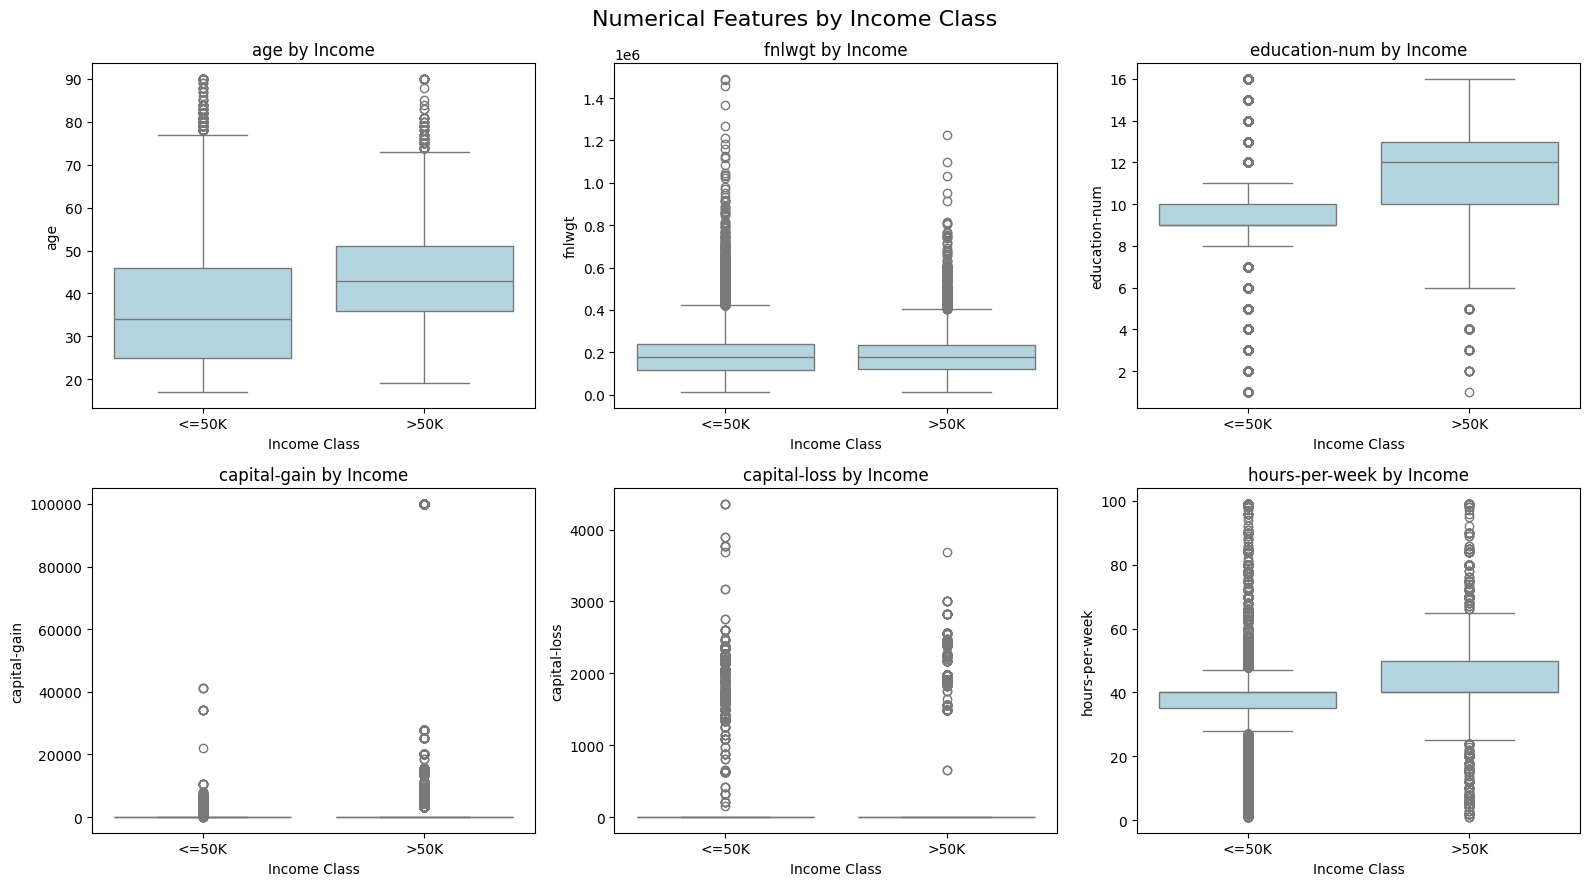

In [14]:
# ============================================================
# Bivariate Analysis - Numerical Boxplots by Income
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(
        data=df,
        x="income",
        y=col,
        order=["<=50K", ">50K"],
        color="lightblue",
        ax=ax
    )

    ax.set_title(f"{col} by Income")
    ax.set_xlabel("Income Class")
    ax.set_ylabel(col)

plt.suptitle(
    "Numerical Features by Income Class",
    fontsize=16
)

plt.tight_layout()
plt.show()

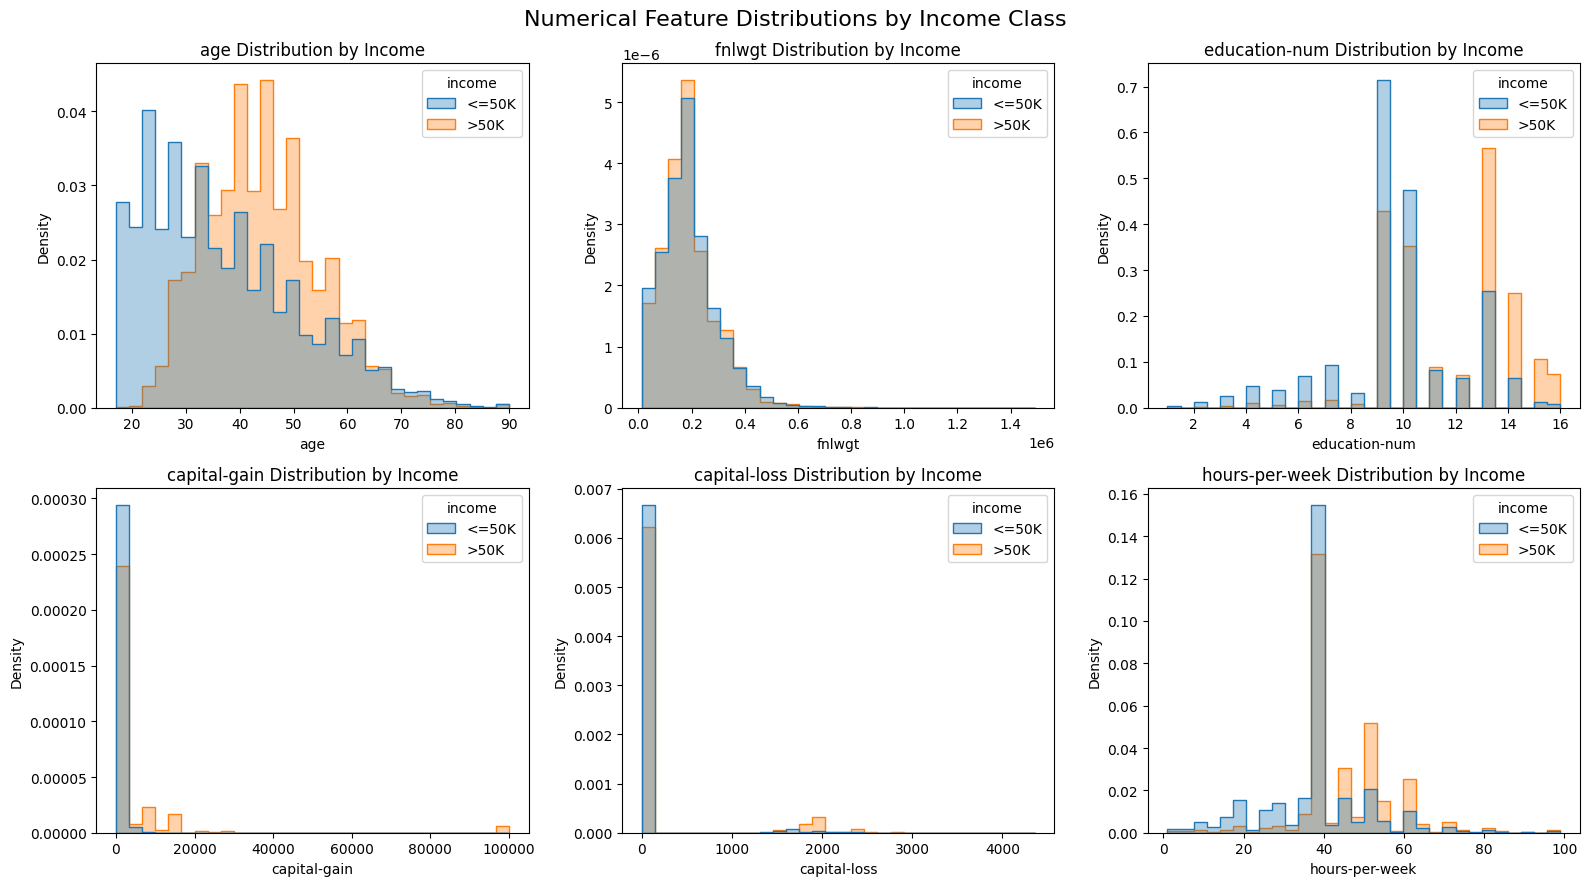

In [16]:
# ============================================================
# Bivariate Analysis - Numerical Distributions by Income
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flat, num_cols):

    sns.histplot(
        data=df,
        x=col,
        hue="income",
        hue_order=["<=50K", ">50K"],
        bins=30,
        stat="density",
        common_norm=False,
        element="step",
        alpha=0.35,
        ax=ax
    )

    ax.set_title(f"{col} Distribution by Income")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")

plt.suptitle(
    "Numerical Feature Distributions by Income Class",
    fontsize=16
)

plt.tight_layout()
plt.show()

#### Numerical Features vs. Income — Findings

The grouped descriptive statistics, boxplots, and histograms reveal several differences between the two income classes.

| Feature | Key Findings |
|---|---|
| `age` | Higher-income individuals tend to be older, with a median age of 43 versus 34 years. Both distributions overlap substantially. |
| `fnlwgt` | Nearly identical distributions across income classes, suggesting limited individual predictive value. |
| `education-num` | Higher-income individuals have greater educational attainment, with a median of 12 versus 9. The distributions show a noticeable shift toward higher education levels. |
| `capital-gain` | Mean capital gains are substantially higher in the `>50K` class ($4,042 vs. $147), although both medians are zero. Extreme values strongly influence the means. |
| `capital-loss` | Higher-income individuals report greater average capital losses ($194 vs. $54), but both distributions remain heavily concentrated at zero. |
| `hours-per-week` | Higher-income individuals work more hours on average (45.45 vs. 38.84), although both groups have a median of 40 hours. |

**Key conclusions:**

- **Potential predictors:** Age, education level, capital gains, capital losses, and working hours show noticeable associations with income.
- **Limited separation:** `fnlwgt` exhibits substantial overlap and little difference between income classes.
- **Financial distributions:** Capital gains and losses remain highly skewed, with zero medians in both classes. Their positive values warrant separate investigation.
- **Distribution overlap:** Although several features differ between income classes, no single numerical feature provides complete separation.

**Overall conclusion:** Educational attainment, age, working hours, and financial variables appear potentially informative for income prediction. However, these are descriptive associations rather than confirmed measures of predictive importance. Their actual contributions will be evaluated during model training and validation.

### Categorical Features vs. Income

This section examines the relationship between categorical features and income classification.

We will calculate the proportion of individuals earning more than $50K within each category, identify differences in income distributions, and investigate potentially informative categorical predictors.

Because the target variable is imbalanced, normalized proportions will be used to compare categories independently of their sample sizes.

In [20]:
# ============================================================
# Bivariate Analysis - Categorical Features vs. Income
# ============================================================

# Select categorical predictors, excluding the target
cat_cols = df.select_dtypes(
    include=["object", "str", "category"]
).columns.drop("income").tolist()

for col in cat_cols:
    print(f"\n{'=' * 55}")
    print(f"Feature: {col}")
    print(f"{'=' * 55}")

    # Calculate income distribution within each category
    income_by_category = pd.crosstab(
        df[col].fillna("Missing"),
        df["income"],
        normalize="index"
    ) * 100

    # Include the number of observations per category
    income_by_category["count"] = (
        df[col].fillna("Missing").value_counts()
    )

    # Sort by percentage earning more than $50K
    income_by_category = income_by_category.sort_values(
        by=">50K",
        ascending=False
    )

    display(income_by_category.round(2))


Feature: workclass


income,<=50K,>50K,count
workclass,,,
Self-emp-inc,44.66,55.34,1695
Federal-gov,60.82,39.18,1432
Local-gov,70.44,29.56,3136
Self-emp-not-inc,72.11,27.89,3862
State-gov,73.25,26.75,1981
Private,78.21,21.79,33906
Without-pay,90.48,9.52,21
Missing,90.53,9.47,2799
Never-worked,100.00,0.00,10



Feature: education


income,<=50K,>50K,count
education,,,
Prof-school,26.02,73.98,834
Doctorate,27.44,72.56,594
Masters,45.09,54.91,2657
Bachelors,58.72,41.28,8025
Assoc-acdm,74.20,25.80,1601
Assoc-voc,74.67,25.33,2061
Some-college,81.04,18.96,10878
HS-grad,84.14,15.86,15784
12th,92.69,7.31,657



Feature: marital-status


income,<=50K,>50K,count
marital-status,,,
Married-civ-spouse,55.39,44.61,22379
Married-AF-spouse,62.16,37.84,37
Divorced,89.88,10.12,6633
Married-spouse-absent,90.76,9.24,628
Widowed,91.57,8.43,1518
Separated,93.53,6.47,1530
Never-married,95.45,4.55,16117


... (6 outputs left out)


Feature: sex


income,<=50K,>50K,count
sex,,,
Male,69.62,30.38,32650
Female,89.07,10.93,16192



Feature: native-country


income,<=50K,>50K,count
native-country,,,
France,57.89,42.11,38
India,58.94,41.06,151
Taiwan,60.00,40.00,65
Iran,62.71,37.29,59
England,62.99,37.01,127
Greece,63.27,36.73,49
Japan,65.22,34.78,92
Yugoslavia,65.22,34.78,23
Canada,65.38,34.62,182


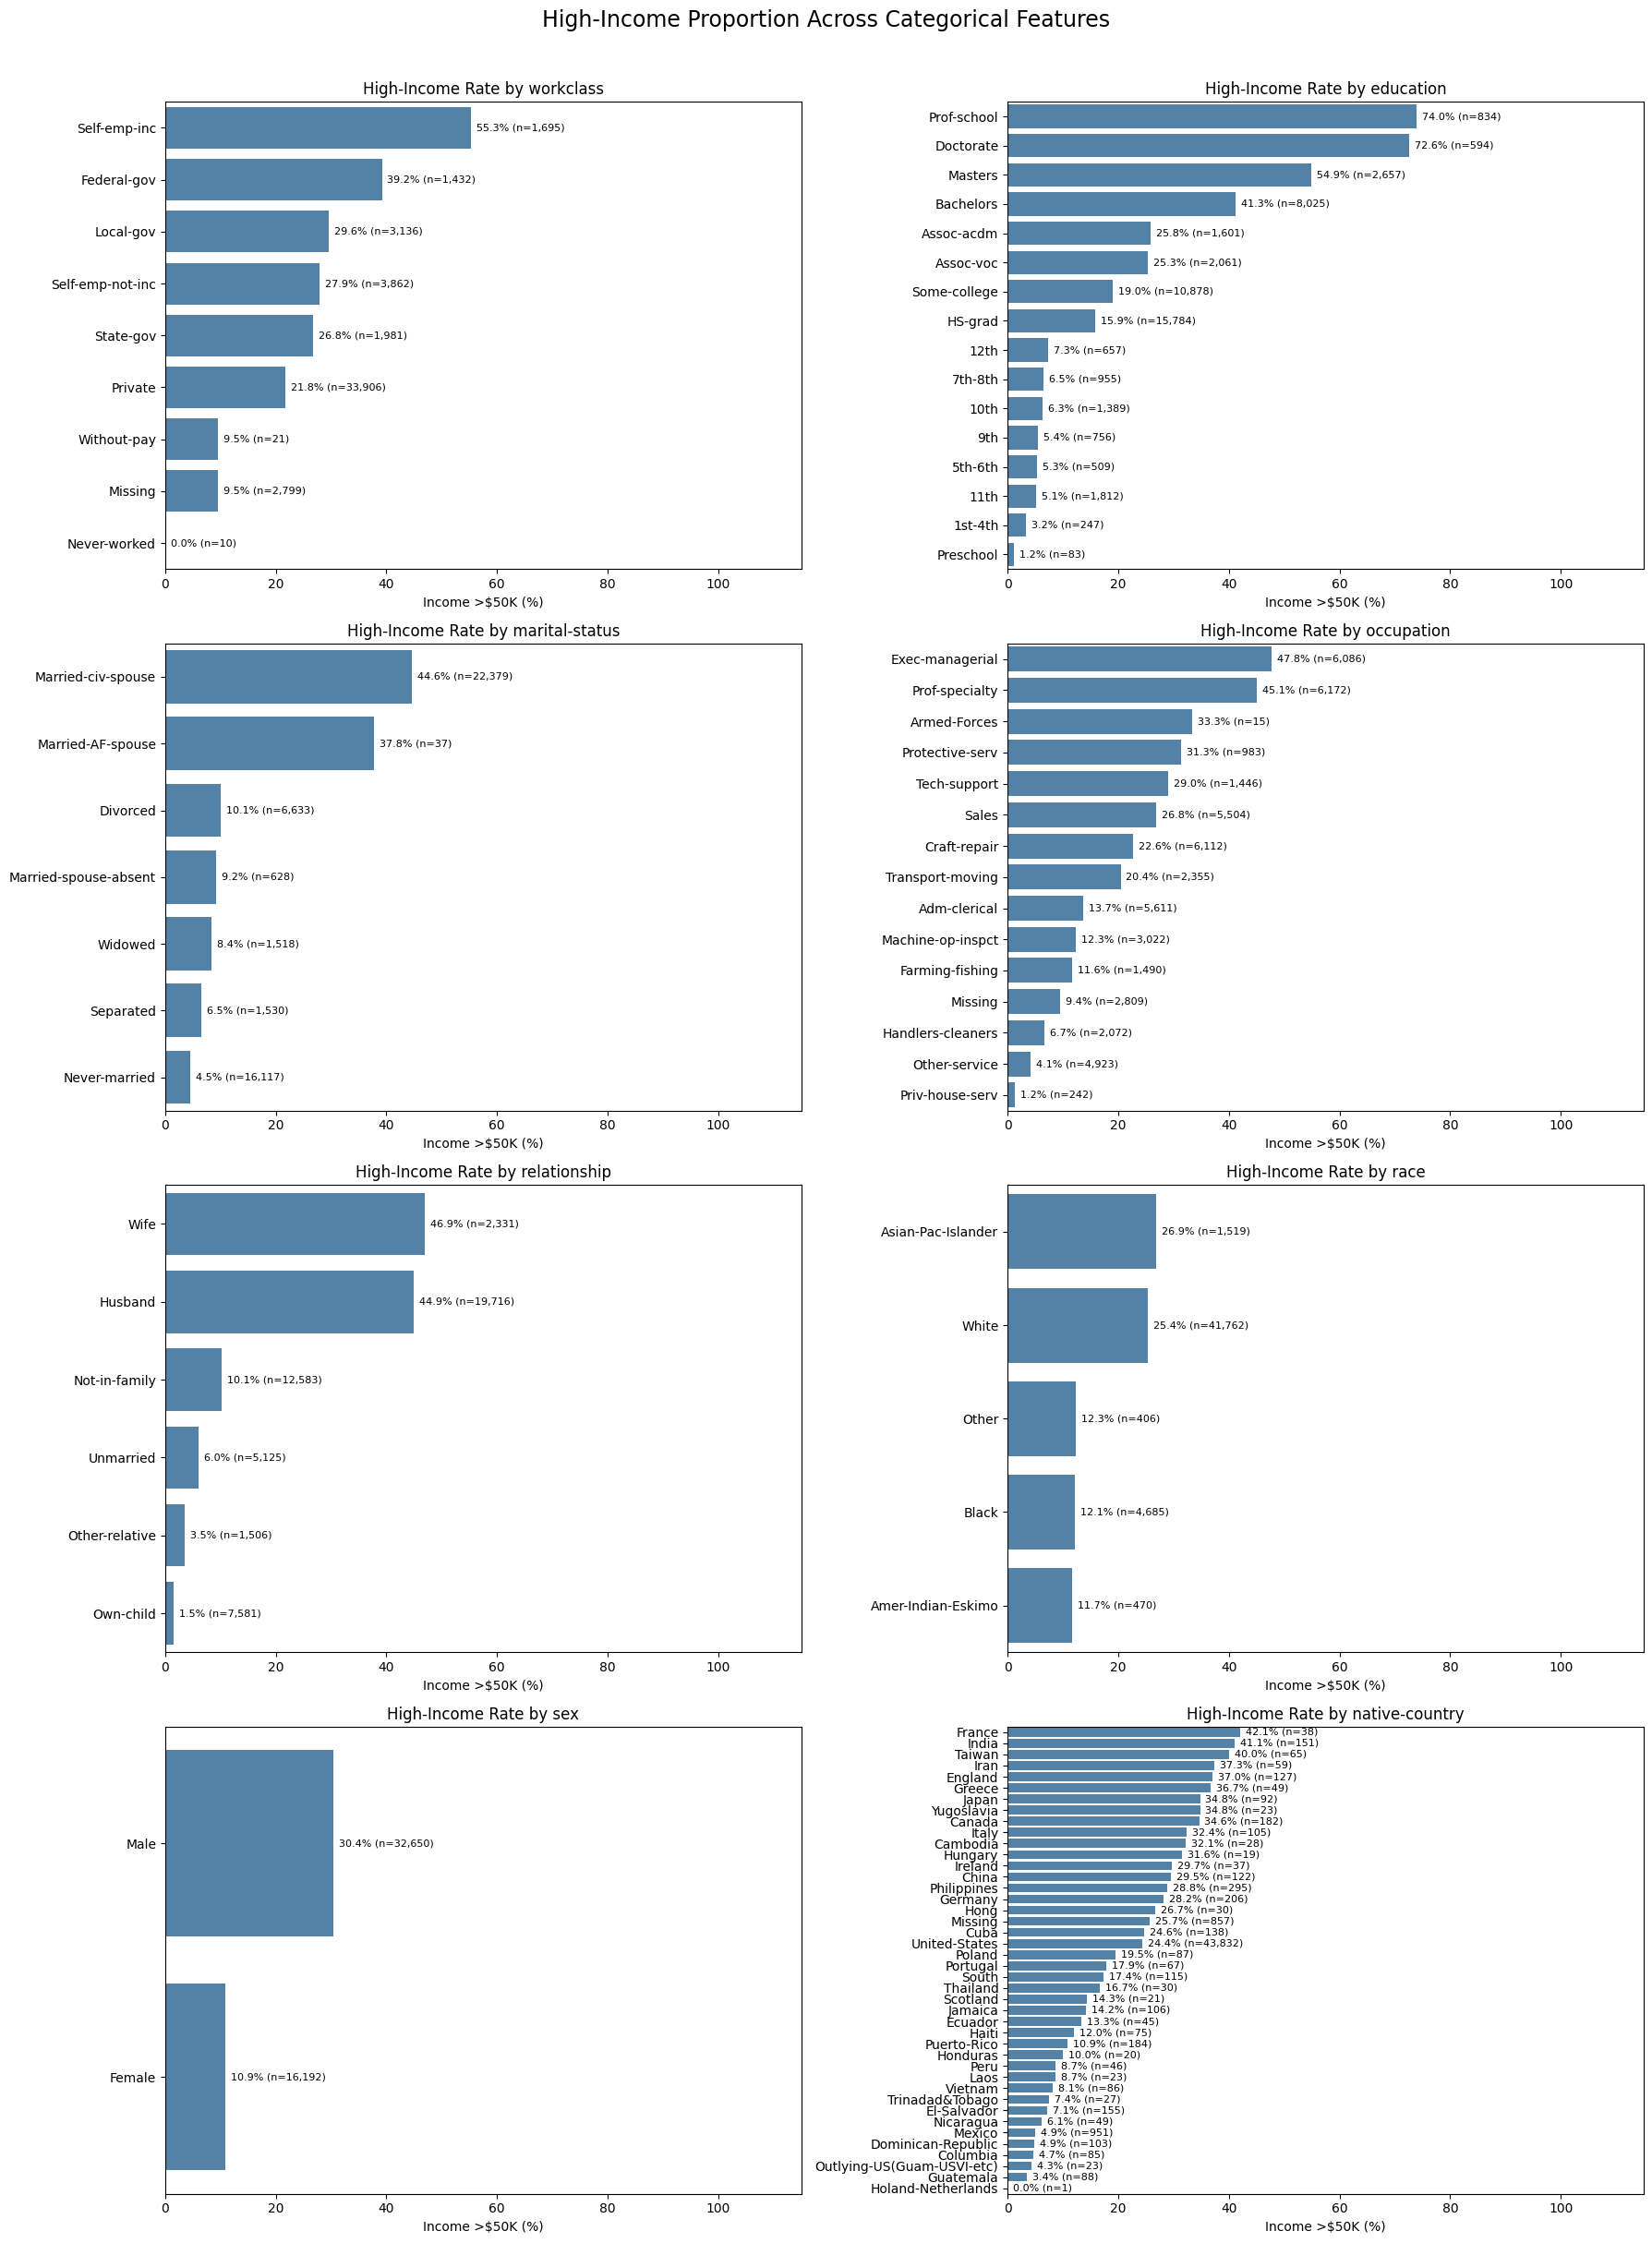

In [19]:
# ============================================================
# Bivariate Analysis - High-Income Rate by Category
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Select categorical predictors, excluding the target
cat_cols = df.select_dtypes(
    include=["object", "str", "category"]
).columns.drop("income").tolist()

# Create subplot grid
fig, axes = plt.subplots(4, 2, figsize=(18, 24))

for ax, col in zip(axes.flat, cat_cols):

    # Replace missing values for analysis only
    categories = df[col].fillna("Missing")

    # Calculate high-income percentage and category size
    summary = pd.DataFrame({
        "category": categories,
        "high_income": df["income"].eq(">50K")
    }).groupby("category")["high_income"].agg(
        rate="mean",
        count="size"
    ).reset_index()

    # Convert proportions to percentages
    summary["rate"] *= 100

    # Sort by high-income rate
    summary = summary.sort_values("rate", ascending=False)

    # Draw horizontal bar chart
    sns.barplot(
        data=summary,
        x="rate",
        y="category",
        color="steelblue",
        ax=ax
    )

    # Add percentage and sample size labels
    for i, row in enumerate(summary.itertuples()):
        ax.text(
            row.rate + 1,
            i,
            f"{row.rate:.1f}% (n={row.count:,})",
            va="center",
            fontsize=8
        )

    ax.set_title(f"High-Income Rate by {col}")
    ax.set_xlabel("Income >$50K (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 115)

plt.suptitle(
    "High-Income Proportion Across Categorical Features",
    fontsize=17,
    y=1.01
)

plt.tight_layout()
plt.show()

### 3.5.3 Categorical Features vs. Income — Visual Analysis: Findings

The normalized bar charts reveal substantial differences in high-income proportions across categorical features. These findings reinforce the patterns identified in the frequency tables and highlight potentially informative predictors.

#### Key Findings

| Feature | Main Observations |
|---|---|
| `workclass` | Incorporated self-employed individuals have the highest high-income rate (55.3%), followed by federal government employees (39.2%). Private-sector employees have a rate of 21.8%. |
| `education` | A strong relationship is observed between educational attainment and income. Professional school graduates (74.0%) and doctorate holders (72.6%) have the highest rates, compared with 15.9% for high-school graduates. |
| `marital-status` | Married-civ-spouse individuals have a high-income rate of 44.6%, substantially higher than never-married individuals (4.5%). |
| `occupation` | Executive-managerial (47.8%) and professional-specialty (45.1%) occupations have the highest rates among well-represented occupational categories. |
| `relationship` | Individuals classified as Wife (46.9%) or Husband (44.9%) have considerably higher rates than those classified as Own-child (1.5%). |
| `race` | High-income rates vary across recorded racial categories, ranging from 11.7% to 26.9%. These differences are descriptive and may reflect multiple socioeconomic factors. |
| `sex` | The Male category has a high-income rate of 30.4%, compared with 10.9% for Female, indicating a substantial difference within this dataset. |
| `native-country` | Considerable variation exists across countries. India (41.1%) and France (42.1%) show relatively high rates, but France has only 38 observations. The United States dominates the dataset with 43,832 observations and a 24.4% high-income rate. |

#### Important Considerations

**1. Strong categorical associations**

Education, occupation, marital status, relationship, and workclass exhibit substantial differences in high-income rates between categories. These features are promising candidates for predictive modeling, although their independent contributions remain unverified.

**2. Category sample sizes**

Several categories contain very few observations, making their estimated high-income rates potentially unstable. For example, `Holand-Netherlands` contains only one observation, while `Armed-Forces` contains 15. Rare categories may require special treatment during preprocessing.

**3. Potential feature redundancy**

`marital-status` and `relationship` contain related household information, while `education` and `education-num` represent the same underlying educational attainment. These relationships should be examined during multivariate analysis and feature selection.

**4. Demographic differences and fairness**

Differences in income proportions across `race` and `sex` are observational associations, not evidence of causation. These features should be evaluated carefully for potential bias, fairness implications, and suitability for the intended prediction application.

**5. Class imbalance and missing information**

The normalized charts account for differences in category sizes, making comparisons more meaningful than raw counts alone. Missing `workclass` and `occupation` values also show relatively low high-income rates (approximately 9.5%), supporting the earlier finding that missingness may contain predictive information.

#### Conclusions and Modeling Considerations

- **Feature selection:** Prioritize further investigation of education, occupation, workclass, and household characteristics.
- **Categorical encoding:** Consider one-hot encoding and appropriate handling of rare categories, particularly for `native-country`.
- **Missing values:** Preserve missingness information using a dedicated `"Unknown"` category as an initial preprocessing strategy.
- **Redundancy:** Evaluate overlapping categorical features before finalizing the model.
- **Fairness:** Assess model performance across demographic groups rather than relying exclusively on aggregate metrics.

**Overall conclusion:** The visual analysis identifies substantial associations between categorical predictors and income classification. Education, occupation, employment type, and household characteristics appear particularly informative. However, these findings remain descriptive; statistical association measures and model validation will be required to quantify their importance and predictive usefulness.

### Statistical Association Analysis

This section evaluates the statistical relationships between categorical predictors and the binary income target.

Two methods will be applied:

- **Chi-square test of independence (χ²):** Tests whether the distribution of income is independent of each categorical feature.
- **Cramér's V:** Quantifies the strength of the association, ranging from 0 (no association) to 1 (perfect association).

A significance level of **α = 0.05** will be used. However, statistical significance does not necessarily imply a strong or practically meaningful relationship, particularly with a large dataset.

The analysis will help identify potentially informative categorical predictors and guide subsequent feature selection and model development.

In [ ]:
# ============================================================
# Statistical Association - Chi-Square and Cramér's V
# ============================================================

# Store association results
association_results = []

# Analyze each categorical predictor
for col in cat_cols:

    # Build contingency table, including missing values
    contingency = pd.crosstab(
        df[col].fillna("Missing"),
        df["income"]
    )

    # Chi-square test of independence
    chi2, p_value, dof, expected = chi2_contingency(
        contingency
    )

    # Calculate Cramér's V
    n = contingency.to_numpy().sum()
    r, c = contingency.shape

    cramers_v = np.sqrt(
        chi2 / (n * min(r - 1, c - 1))
    )

    # Check chi-square expected frequency assumption
    low_expected_pct = (expected < 5).mean() * 100

    association_results.append({
        "feature": col,
        "chi2": chi2,
        "p_value": p_value,
        "cramers_v": cramers_v,
        "dof": dof,
        "expected_below_5_pct": low_expected_pct
    })

# Create results DataFrame
association_df = pd.DataFrame(association_results)

# Sort by association strength
association_df = association_df.sort_values(
    "cramers_v", ascending=False
)

display(association_df.round(4))

,feature,chi2,p_value,cramers_v,dof,expected_below_5_pct
4,relationship,10088.7225,0.0,0.4545,5,0.0000
2,marital-status,9816.0150,0.0,0.4483,6,0.0000
1,education,6537.9730,0.0,0.3659,15,0.0000
3,occupation,5983.1639,0.0,0.3500,14,3.3333
6,sex,2248.8477,0.0,0.2146,1,0.0000
0,workclass,1610.7524,0.0,0.1816,8,5.5556
5,race,487.0263,0.0,0.0999,4,0.0000
7,native-country,452.2290,0.0,0.0962,41,4.7619


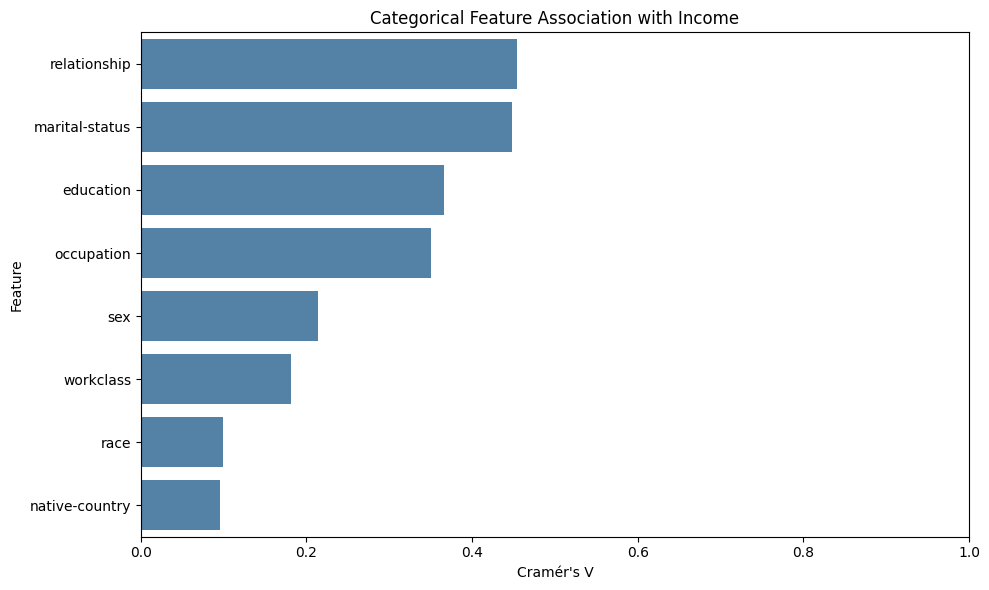

In [ ]:
# ============================================================
# Statistical Association - Cramér's V Visualization
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=association_df,
    x="cramers_v",
    y="feature",
    color="steelblue"
)

plt.title("Categorical Feature Association with Income")
plt.xlabel("Cramér's V")
plt.ylabel("Feature")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

#### Statistical Association Analysis — Findings

Chi-square tests and Cramér's V were used to evaluate associations between categorical predictors and the binary income target.

All eight categorical features showed statistically significant associations with income (p < 0.05). However, association strength varied considerably.

**Key findings:**

- **Strongest associations:** `relationship` (V = 0.4545) and `marital-status` (V = 0.4483) showed the highest association strengths.
- **Moderate associations:** `education` (V = 0.3659) and `occupation` (V = 0.3500) demonstrated meaningful relationships with income.
- **Weaker associations:** `sex` (V = 0.2146) and `workclass` (V = 0.1816) showed weaker relationships.
- **Very weak associations:** `race` (V = 0.0999) and `native-country` (V = 0.0962) had the lowest association strengths.

**Statistical considerations:**

- All chi-square tests were statistically significant, but statistical significance does not imply strong predictive value.
- Expected-frequency diagnostics were generally acceptable, although rare categories warrant additional examination.
- Associations are marginal and do not account for interactions or confounding variables.
- Overlapping information between `relationship` and `marital-status` may introduce feature redundancy.

**Conclusion:** Household characteristics, education, and occupation exhibit the strongest categorical associations with income. These findings support further investigation during multivariate analysis, but feature selection should ultimately depend on validated model performance rather than association strength alone.

### Numerical Statistical Association Analysis

This section evaluates the statistical relationships between numerical predictors and the binary income target.

Two complementary methods will be applied:

- **Point-biserial correlation:** Measures the direction and strength of the linear association between a numerical feature and income.
- **Mann–Whitney U test:** Evaluates whether numerical values tend to differ between the two income groups using ranks rather than raw values.

Rank-biserial correlation will also be calculated as an effect-size measure for the Mann–Whitney U test.

A significance level of α = 0.05 will be used. Statistical significance and effect size will be interpreted separately, particularly given the dataset's large sample size.

In [ ]:
# ============================================================
# Numerical Statistical Association Analysis
# Point-Biserial Correlation and Mann-Whitney U
# ============================================================



# Select numerical features
num_cols = df.select_dtypes(include="number").columns.tolist()

# Encode binary target for statistical analysis only
# 0 = <=50K, 1 = >50K
y_binary = df["income"].eq(">50K").astype(int)

# Store results
numerical_associations = []

for col in num_cols:

    # Separate observations by income class
    low_income = df.loc[y_binary == 0, col].dropna()
    high_income = df.loc[y_binary == 1, col].dropna()

    # Point-biserial correlation
    r, p_corr = pointbiserialr(
        y_binary,
        df[col]
    )

    # Mann-Whitney U test (two-sided)
    u_stat, p_mw = mannwhitneyu(
        high_income,
        low_income,
        alternative="two-sided",
        method="asymptotic"
    )

    # Rank-biserial correlation:
    # Positive values indicate higher values in the >50K group
    n_high = len(high_income)
    n_low = len(low_income)

    rank_biserial = (
        2 * u_stat / (n_high * n_low)
    ) - 1

    # Store statistics
    numerical_associations.append({
        "feature": col,
        "point_biserial_r": r,
        "point_biserial_p": p_corr,
        "mann_whitney_u": u_stat,
        "mann_whitney_p": p_mw,
        "rank_biserial": rank_biserial
    })

# Create results table
numerical_assoc_df = pd.DataFrame(
    numerical_associations
)

# Sort by absolute point-biserial correlation
numerical_assoc_df = numerical_assoc_df.sort_values(
    "point_biserial_r",
    key=abs,
    ascending=False
)

display(numerical_assoc_df.round(4))

,feature,point_biserial_r,point_biserial_p,mann_whitney_u,mann_whitney_p,rank_biserial
2,education-num,0.3326,0.0000,311010711.5,0.0000,0.4325
0,age,0.2304,0.0000,296257069.5,0.0000,0.3645
5,hours-per-week,0.2277,0.0000,291741763.0,0.0000,0.3437
3,capital-gain,0.2230,0.0000,256072614.5,0.0000,0.1794
4,capital-loss,0.1476,0.0000,231968419.0,0.0000,0.0684
1,fnlwgt,-0.0063,0.1612,215371681.5,0.1897,-0.0080


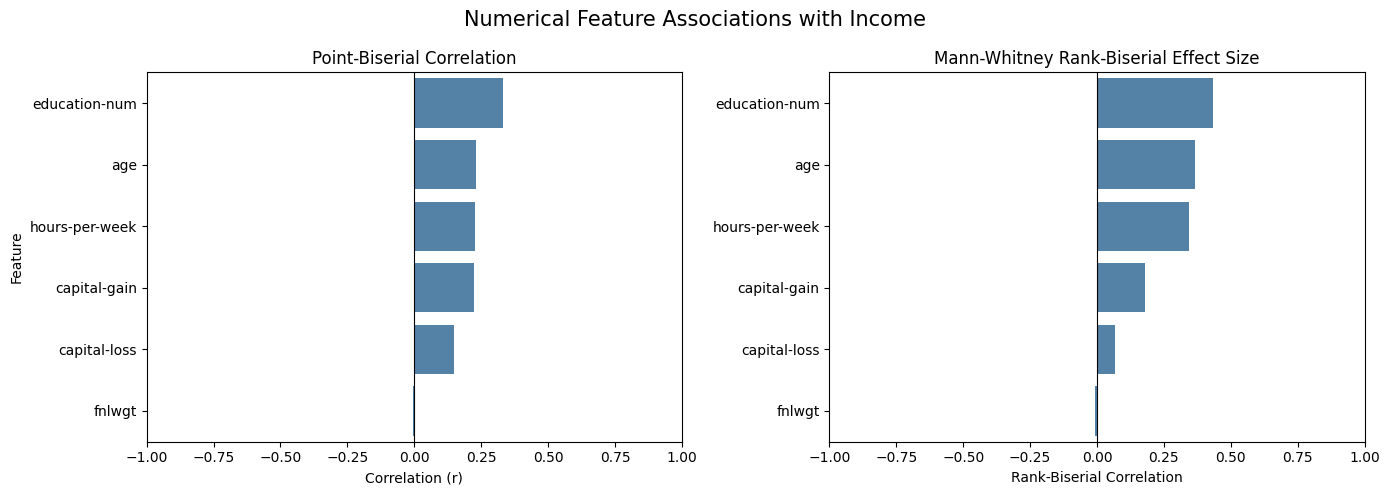

In [ ]:
# ============================================================
# Numerical Associations - Effect Size Comparison
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Point-biserial correlation
sns.barplot(
    data=numerical_assoc_df,
    x="point_biserial_r",
    y="feature",
    color="steelblue",
    ax=axes[0]
)

axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Point-Biserial Correlation")
axes[0].set_xlabel("Correlation (r)")
axes[0].set_ylabel("Feature")
axes[0].set_xlim(-1, 1)

# Rank-biserial correlation
sns.barplot(
    data=numerical_assoc_df,
    x="rank_biserial",
    y="feature",
    color="steelblue",
    ax=axes[1]
)

axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Mann-Whitney Rank-Biserial Effect Size")
axes[1].set_xlabel("Rank-Biserial Correlation")
axes[1].set_ylabel("")
axes[1].set_xlim(-1, 1)

plt.suptitle(
    "Numerical Feature Associations with Income",
    fontsize=15
)

plt.tight_layout()
plt.show()

#### Numerical Statistical Association Analysis — Findings

Point-biserial correlation and the Mann–Whitney U test were applied to evaluate relationships between numerical predictors and income.

Five of the six numerical features showed statistically significant associations with income (p < 0.0001), while `fnlwgt` showed no statistically significant association.

| Feature | Point-biserial r | Rank-biserial |
|---|---:|---:|
| `education-num` | 0.3326 | 0.4325 |
| `age` | 0.2304 | 0.3645 |
| `hours-per-week` | 0.2277 | 0.3437 |
| `capital-gain` | 0.2230 | 0.1794 |
| `capital-loss` | 0.1476 | 0.0684 |
| `fnlwgt` | -0.0063 | -0.0080 |

**Key findings:**

- **Education:** Exhibits the strongest numerical association with income across both methods.
- **Age and working hours:** Show consistent positive associations with higher income.
- **Capital gains and losses:** Show statistically significant associations, although zero-heavy distributions and extreme values affect the interpretation of effect sizes.
- **Final weight (`fnlwgt`):** Exhibits negligible marginal association with income and is not statistically significant in either test.

**Statistical considerations:**

- Statistical significance does not necessarily imply practical importance or predictive usefulness.
- Rank-based methods are less sensitive to extreme numerical magnitudes, making them useful for skewed features.
- The associations are marginal and do not account for interactions, confounding, or nonlinear relationships.
- Feature importance and selection decisions should ultimately be validated through model performance.

**Conclusion:** Educational attainment, age, working hours, and financial variables show measurable associations with income. `fnlwgt` appears less informative as an individual predictor. These findings provide a foundation for multivariate analysis and subsequent feature engineering.

### Multivariate Analysis

This section examines relationships among predictors to identify potential multicollinearity, redundant information, and feature interactions.

Unlike bivariate analysis, which focused on individual features and income, this phase investigates how predictors relate to one another and how combinations of features may influence income classification.

### Numerical Correlation Analysis

We will calculate Pearson and Spearman correlation matrices to evaluate linear and monotonic relationships among numerical features.

The objectives are to:

- Identify strongly correlated numerical predictors.
- Detect potential feature redundancy.
- Compare linear and rank-based relationships.
- Inform subsequent preprocessing and feature selection decisions.

Correlation does not imply causation, and low correlation does not necessarily indicate an absence of nonlinear relationships.

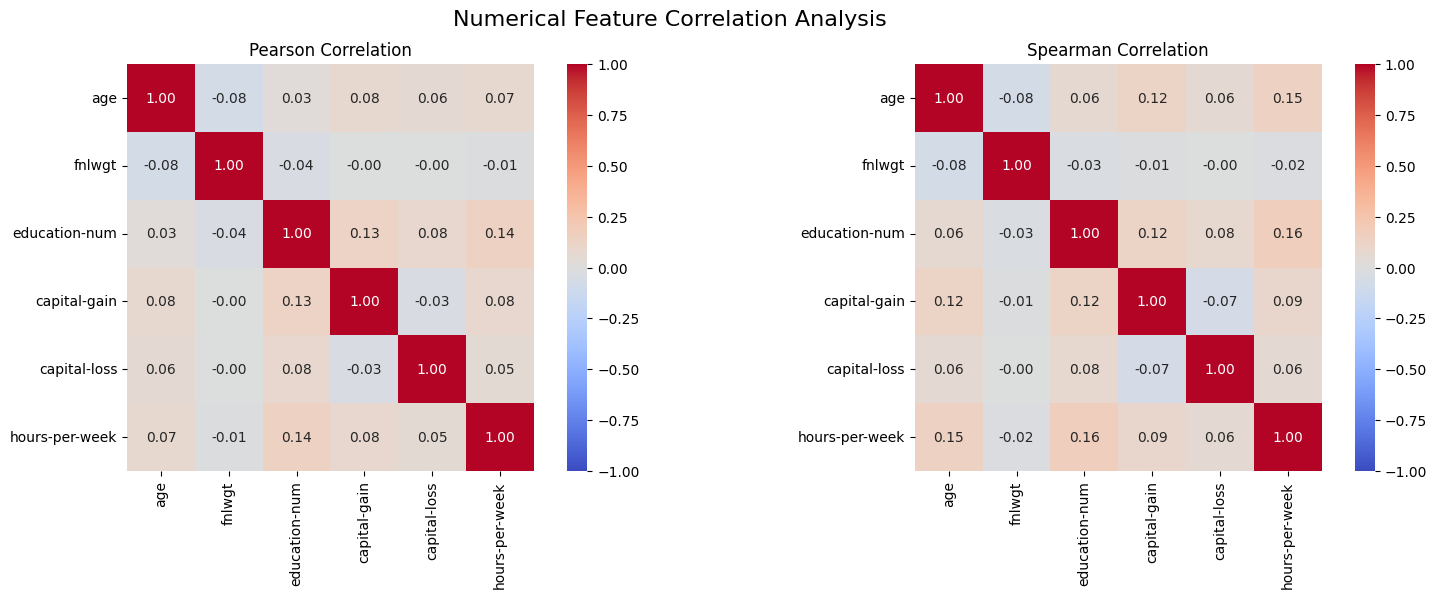

In [34]:
# ============================================================
# Multivariate Analysis - Numerical Correlation Matrices
# ============================================================

# Select numerical predictors (excluding target)
num_cols = df.select_dtypes(include="number").columns.tolist()

# Calculate correlation matrices
pearson_corr = df[num_cols].corr(method="pearson")
spearman_corr = df[num_cols].corr(method="spearman")

# ============================================================
# Multivariate Analysis - Correlation Heatmaps
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Pearson correlation
sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[0]
)

axes[0].set_title("Pearson Correlation")

# Spearman correlation
sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[1]
)

axes[1].set_title("Spearman Correlation")

plt.suptitle(
    "Numerical Feature Correlation Analysis",
    fontsize=16
)

plt.tight_layout()
plt.show()

#### Numerical Correlation Analysis — Findings

Pearson and Spearman correlation matrices were calculated to examine relationships among numerical predictors.

Both methods revealed consistently weak correlations, with maximum absolute coefficients of **0.144 (Pearson)** and **0.164 (Spearman)**.

The strongest relationship was between `education-num` and `hours-per-week`, although its magnitude remained weak.

**Conclusion:** No substantial pairwise numerical correlation or redundancy was identified. The features may provide complementary predictive information, although nonlinear relationships and multivariate dependencies cannot be ruled out. No feature removal is justified based on these results alone.

### 3.6.2 Categorical Feature Relationships

This section investigates associations and potential redundancy among categorical predictors.

We will use Cramér's V to quantify categorical associations and cross-tabulations to examine relationships between selected features.

We will also verify whether `education` and `education-num` contain equivalent information.

The objective is to identify overlapping features that may influence encoding, feature selection, and model interpretation.

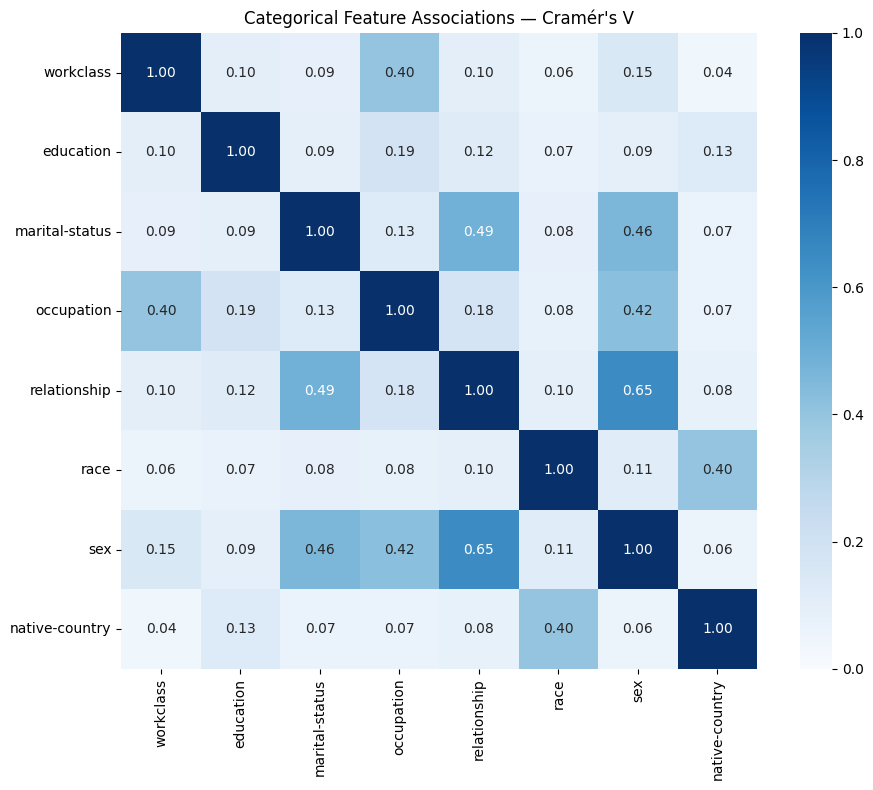

In [36]:
# ============================================================
# Multivariate Analysis - Categorical Association Matrix
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

# Select categorical predictors, excluding income
cat_cols = df.select_dtypes(
    include=["object", "str", "category"]
).columns.drop("income").tolist()

# Function to calculate Cramér's V
def cramers_v(x, y):
    """Calculate Cramér's V between two categorical variables."""

    contingency = pd.crosstab(
        x.fillna("Missing"),
        y.fillna("Missing")
    )

    chi2 = chi2_contingency(
        contingency,
        correction=False
    )[0]

    n = contingency.to_numpy().sum()
    r, c = contingency.shape

    return np.sqrt(
        chi2 / (n * min(r - 1, c - 1))
    )

# Initialize association matrix
cat_corr = pd.DataFrame(
    np.eye(len(cat_cols)),
    index=cat_cols,
    columns=cat_cols
)

# Calculate unique feature pairs
for i, col1 in enumerate(cat_cols):
    for j in range(i + 1, len(cat_cols)):

        value = cramers_v(df[col1], df[cat_cols[j]])

        cat_corr.loc[col1, cat_cols[j]] = value
        cat_corr.loc[cat_cols[j], col1] = value


# ============================================================
# Categorical Association Heatmap
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    cat_corr,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True
)

plt.title("Categorical Feature Associations — Cramér's V")
plt.tight_layout()
plt.show()

#### Categorical Feature Association — Findings

Cramér's V was used to measure associations among categorical predictors and identify potential feature redundancy.

**Key findings:**

- **Strongest association:** `relationship` and `sex` (V = 0.65), indicating substantial overlap in household-role information.
- **Household characteristics:** `marital-status` and `relationship` (V = 0.49), and `marital-status` and `sex` (V = 0.46), show notable associations.
- **Employment characteristics:** `occupation` and `sex` (V = 0.42), and `occupation` and `workclass` (V = 0.40), exhibit moderate associations.
- **Demographic characteristics:** `race` and `native-country` (V = 0.40) show a moderate association.
- **Other relationships:** Most remaining feature pairs exhibit weak associations (V < 0.20).

**Conclusion:** Several categorical predictors contain overlapping information, particularly household and employment characteristics. However, association does not establish complete redundancy. These features should be retained for initial modeling, with their contributions and potential redundancy evaluated during feature selection and validation.

In [37]:
# ============================================================
# Check Redundancy - Education vs. Education-Num
# ============================================================

education_mapping = (
    df.groupby("education")["education-num"]
    .agg(
        unique_values="nunique",
        min_value="min",
        max_value="max",
        count="size"
    )
    .sort_values("min_value")
)

display(education_mapping)

# Check whether each category has a unique numerical mapping
is_consistent = education_mapping["unique_values"].eq(1).all()

# Check whether each numerical value maps back to one category
reverse_consistent = (
    df.groupby("education-num")["education"]
    .nunique()
    .eq(1)
    .all()
)

print(f"Consistent education mapping: {is_consistent}")
print(f"One-to-one mapping: {is_consistent and reverse_consistent}")

,unique_values,min_value,max_value,count
education,,,,
Preschool,1,1,1,83
1st-4th,1,2,2,247
5th-6th,1,3,3,509
7th-8th,1,4,4,955
9th,1,5,5,756
10th,1,6,6,1389
11th,1,7,7,1812
12th,1,8,8,657
HS-grad,1,9,9,15784


Consistent education mapping: True
One-to-one mapping: True


#### Education Feature Redundancy — Findings

The relationship between `education` and `education-num` was examined to determine whether both features encode the same information.

**Results:**
- All 16 education categories map consistently to unique numerical values.
- Each numerical value corresponds to exactly one education category.
- Both consistency checks returned `True`, confirming complete redundancy.

**Modeling implications:**

Including both features is unnecessary from an information perspective. However, the preferred representation depends on the algorithm:

- **`education-num`:** Preserves educational ordering and is suitable for models that can exploit ordinal relationships.
- **`education`:** Allows categorical encoding without imposing a numerical relationship between education levels.

**Conclusion:** The two features are perfectly redundant. We should compare appropriate representations during model development and retain the one that produces better validation performance, rather than automatically including both.

-----

### Feature Interaction Analysis

This section investigates how combinations of predictors relate to the probability of earning more than $50K.

We will examine selected interactions involving education, age, occupation, marital status, and working hours.

The objectives are to:

- Identify income patterns that may not be apparent from individual feature analyses.
- Examine whether associations differ across population subgroups.
- Identify potentially useful feature interactions for machine learning.
- Inform feature engineering decisions during model development.

These analyses are exploratory and do not establish causation or confirm statistical interactions.

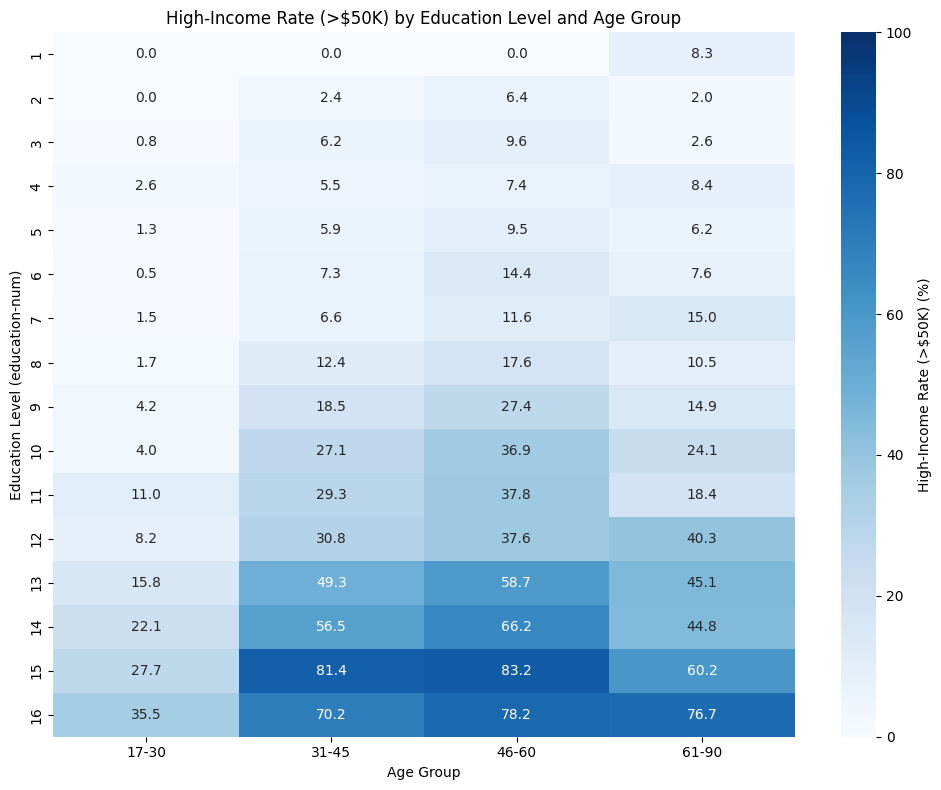

In [58]:
# ============================================================
# Feature Interaction - Education and Age vs. Income
# ============================================================

# Create a temporary analysis DataFrame
eda_df = df.copy()

# Binary target for calculating high-income proportions
eda_df["high_income"] = eda_df["income"].eq(">50K").astype(int)

# Create age groups for exploratory analysis
eda_df["age_group"] = pd.cut(
    eda_df["age"],
    bins=[16, 30, 45, 60, 90],
    labels=["17-30", "31-45", "46-60", "61-90"],
    include_lowest=True
)

# Calculate high-income rate by education and age group
education_age = (
    eda_df.groupby(
        ["education-num", "age_group"],
        observed=True
    )["high_income"]
    .agg(rate="mean", count="size")
    .reset_index()
)

# Convert proportions to percentages
education_age["rate"] *= 100

# Pivot for heatmap
education_age_pivot = education_age.pivot(
    index="education-num",
    columns="age_group",
    values="rate"
)

# Visualize
plt.figure(figsize=(10, 8))

sns.heatmap(
    education_age_pivot,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "High-Income Rate (>$50K) (%)"}

)

plt.title("High-Income Rate (>$50K) by Education Level and Age Group")
plt.xlabel("Age Group")
plt.ylabel("Education Level (education-num)")

plt.tight_layout()
plt.show()

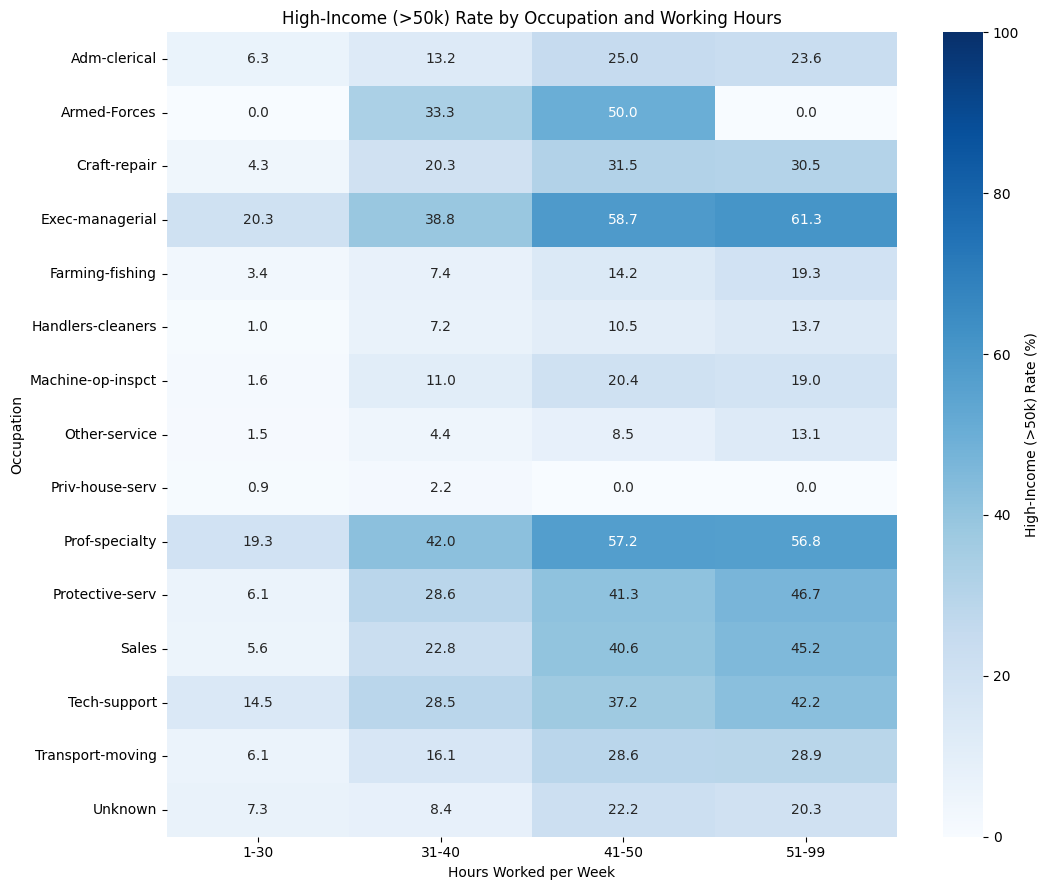

In [ ]:
# ============================================================
# Feature Interaction - Occupation and Working Hours
# ============================================================

# Create working-hour groups
eda_df["hours_group"] = pd.cut(
    eda_df["hours-per-week"],
    bins=[0, 30, 40, 50, 99],
    labels=["1-30", "31-40", "41-50", "51-99"],
    include_lowest=True
)

# Calculate high-income (>50k) rate by occupation and hours
occupation_hours = (
    eda_df.groupby(
        ["occupation", "hours_group"],
        observed=True,
        dropna=False
    )["high_income"]
    .agg(rate="mean", count="size")
    .reset_index()
)

occupation_hours["rate"] *= 100

occupation_hours.fillna("Unknown", inplace=True)

# Create pivot table
occupation_hours_pivot = occupation_hours.pivot(
    index="occupation",
    columns="hours_group",
    values="rate"
)

# Visualize
plt.figure(figsize=(11, 9))

sns.heatmap(
    occupation_hours_pivot,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "High-Income Rate (>$50k) (%)"}

)

plt.title("High-Income Rate (>$50k) by Occupation and Working Hours")
plt.xlabel("Hours Worked per Week")
plt.ylabel("Occupation")

plt.tight_layout()
plt.show()

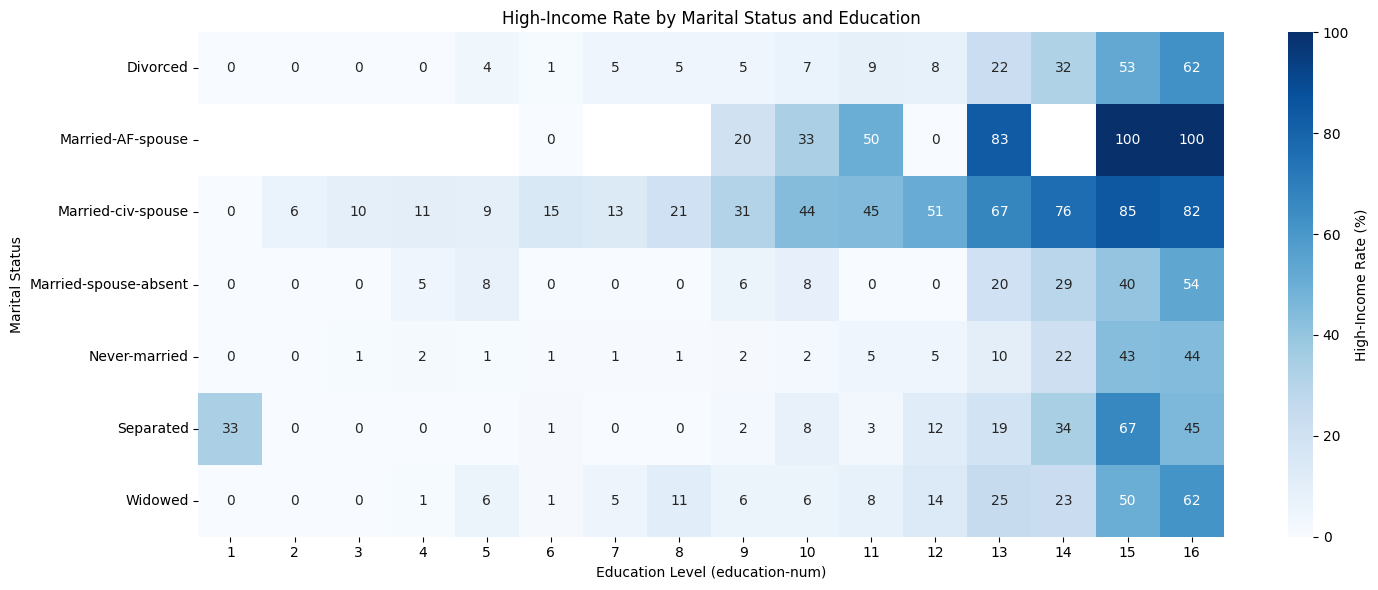

In [ ]:
# ============================================================
# Feature Interaction - Marital Status and Education
# ============================================================

marital_education = (
    eda_df.groupby(
        ["marital-status", "education-num"],
        observed=True
    )["high_income"]
    .agg(rate="mean", count="size")
    .reset_index()
)

marital_education["rate"] *= 100

# Create pivot table
marital_education_pivot = marital_education.pivot(
    index="marital-status",
    columns="education-num",
    values="rate"
)

# Visualize
plt.figure(figsize=(15, 6))

sns.heatmap(
    marital_education_pivot,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "High-Income Rate ($50K) (%)"}

)

plt.title("High-Income Rate ($50K) by Marital Status and Education")
plt.xlabel("Education Level (education-num)")
plt.ylabel("Marital Status")

plt.tight_layout()
plt.show()

In [56]:
# ============================================================
# Feature Interaction - Subgroup Sample Size Diagnostics
# ============================================================

interaction_results = {
    "Education x Age": education_age,
    "Occupation x Hours": occupation_hours,
    "Marital Status x Education": marital_education
}

for name, result in interaction_results.items():

    small_groups = (result["count"] < 30).sum()

    print(f"{name}")
    print(f"  Total observed groups: {len(result)}")
    print(f"  Groups with n < 30: {small_groups}")
    print(f"  Minimum group size: {result['count'].min()}")
    print()

Education x Age
  Total observed groups: 64
  Groups with n < 30: 4
  Minimum group size: 12

Occupation x Hours
  Total observed groups: 60
  Groups with n < 30: 6
  Minimum group size: 1

Marital Status x Education
  Total observed groups: 104
  Groups with n < 30: 34
  Minimum group size: 1



#### Feature Interaction Analysis — Findings

Three feature combinations were examined to investigate how income distributions vary across population subgroups.

**Key findings:**

- **Education × Age:** Higher educational attainment is associated with higher income rates, particularly among individuals aged 31–60. Only 4 of 64 subgroups had fewer than 30 observations.
- **Occupation × Working Hours:** Higher working hours generally correspond to higher income rates, although the magnitude varies across occupations. 6 of 60 subgroups had fewer than 30 observations.
- **Marital Status × Education:** Educational attainment and marital status jointly distinguish income groups. However, 34 of 104 subgroups had fewer than 30 observations, limiting the reliability of some estimates.

**Modeling implications:**

These patterns suggest that combinations of predictors may provide useful information beyond individual feature associations. Age, education, occupation, working hours, and marital status are candidates for interaction-based feature engineering.

However, the observed differences are descriptive and do not establish statistically significant interactions. Their predictive value must be evaluated using validation data.

**Conclusion:** Multivariate analysis revealed meaningful subgroup differences in income distributions. Education and age, along with occupation and working hours, appear particularly promising for further investigation. Small-sample combinations should be treated cautiously.

-----

### 3.6.4 Capital Gain and Loss — Zero-Inflation Analysis

Both `capital-gain` and `capital-loss` exhibit highly right-skewed distributions, with a median of zero.

This section investigates the prevalence of zero values, the distribution of positive amounts, and their associations with income.

The objective is to distinguish legitimate zeros from potential data-quality issues and determine whether these features may benefit from specialized transformations or feature engineering.

In [64]:
# ============================================================
# Capital Gain and Loss - Zero-Inflation Analysis
# ============================================================

financial_cols = ["capital-gain", "capital-loss"]

for col in financial_cols:
    total = len(df)
    zeros = (df[col] == 0).sum()
    positive = (df[col] > 0).sum()

    print(f"\n{col}")
    print(f"Zero values: {zeros:,} ({zeros / total:.2%})")
    print(f"Positive values: {positive:,} ({positive / total:.2%})")
    print(f"Unique positive values: {df.loc[df[col] > 0, col].nunique()}")

    print("\nPositive-value statistics:")
    display(
        df.loc[df[col] > 0, col]
        .describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99])
        .round(2)
    )


capital-gain
Zero values: 44,807 (91.74%)
Positive values: 4,035 (8.26%)
Unique positive values: 122

Positive-value statistics:


count     4035.00
mean     13061.67
std      22711.24
min        114.00
25%       3411.00
50%       7298.00
75%      13550.00
90%      15024.00
95%      99999.00
99%      99999.00
max      99999.00
Name: capital-gain, dtype: float64


capital-loss
Zero values: 46,560 (95.33%)
Positive values: 2,282 (4.67%)
Unique positive values: 98

Positive-value statistics:


count    2282.00
mean     1872.83
std       364.05
min       155.00
25%      1672.00
50%      1887.00
75%      1977.00
90%      2339.00
95%      2415.00
99%      2824.00
max      4356.00
Name: capital-loss, dtype: float64

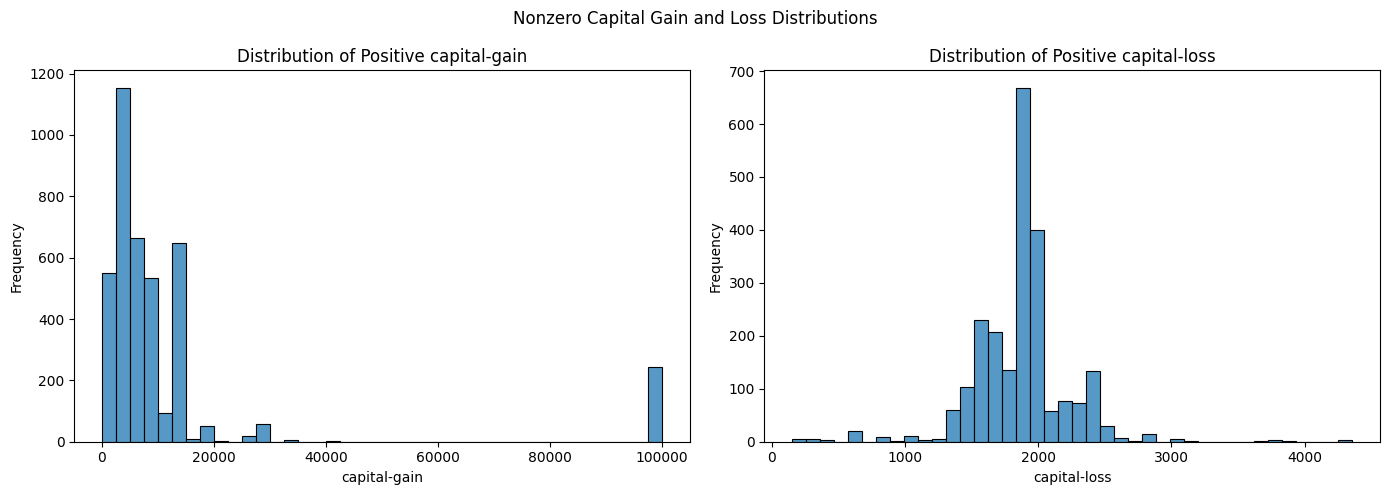

In [60]:
# ============================================================
# Positive Capital Gain and Loss Distributions
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, financial_cols):

    positive_values = df.loc[df[col] > 0, col]

    sns.histplot(
        positive_values,
        bins=40,
        ax=ax
    )

    ax.set_title(f"Distribution of Positive {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.suptitle("Nonzero Capital Gain and Loss Distributions")
plt.tight_layout()
plt.show()

In [65]:
# ============================================================
# Capital Gain and Loss - Association with Income
# ============================================================

for col in financial_cols:

    # Create a temporary zero/nonzero indicator
    status = df[col].gt(0).map({
        False: "Zero",
        True: "Positive"
    })

    # Calculate class proportions
    summary = pd.crosstab(
        status,
        df["income"],
        normalize="index"
    ) * 100

    # Add observation counts
    summary["count"] = status.value_counts()

    print(f"\n{col} vs. Income")
    print(summary.round(2))


capital-gain vs. Income
income        <=50K   >50K  count
capital-gain                     
Positive      38.27  61.73   4035
Zero          79.48  20.52  44807

capital-loss vs. Income
income        <=50K   >50K  count
capital-loss                     
Positive      49.87  50.13   2282
Zero          77.36  22.64  46560


In [66]:
# ============================================================
# Capital Gain and Loss - Joint Occurrence
# ============================================================

gain_positive = df["capital-gain"] > 0
loss_positive = df["capital-loss"] > 0

joint_summary = pd.crosstab(
    gain_positive,
    loss_positive,
    rownames=["Capital Gain > 0"],
    colnames=["Capital Loss > 0"],
    margins=True
)

print(joint_summary)

Capital Loss > 0  False  True    All
Capital Gain > 0                    
False             42525  2282  44807
True               4035     0   4035
All               46560  2282  48842


In [68]:
# Examine the unusual maximum capital-gain value
max_gain = df["capital-gain"].max()

max_gain_rows = df[df["capital-gain"] == max_gain]

print(f"Maximum capital gain: {max_gain:,}")
print(f"Observations: {len(max_gain_rows):,}")
print(f"Percentage of dataset: {len(max_gain_rows) / len(df):.2%}")

print("\nIncome distribution at maximum gain:")
print(max_gain_rows["income"].value_counts(normalize=True).mul(100).round(2))

Maximum capital gain: 99,999
Observations: 244
Percentage of dataset: 0.50%

Income distribution at maximum gain:
income
>50K    100.0
Name: proportion, dtype: float64


### 3.6.4 Capital Gain and Loss — Findings

Both financial features exhibit substantial zero-inflation: **91.74% of `capital-gain`** and **95.33% of `capital-loss`** observations are zero.

**Key findings:**

- Positive capital gains remain highly right-skewed, with a prominent concentration at $99,999 that warrants further investigation.
- Positive capital losses are more concentrated, with a median of $1,887.
- Observations with positive capital gains have a high-income rate of **61.73%**, compared with **20.52%** for zero gains.
- Observations with positive capital losses have a high-income rate of **50.13%**, compared with **22.64%** for zero losses.
- Capital gains and losses are mutually exclusive in the dataset: no observation contains positive values for both variables.

**Modeling implications:**

The zero values appear to represent a meaningful absence of reported gains or losses rather than missing data and should be preserved.

Both features demonstrate substantial associations with income despite their sparse distributions. Potential preprocessing approaches include `log1p` transformations, binary presence indicators, and a combined gain/loss status feature.

**Additional finding — Maximum Capital Gain**

The maximum recorded capital gain of $99,999 occurs in 244 observations (0.50% of the dataset), all belonging to the `>50K` income class.

This indicates an exceptionally strong association between this specific value and the target. The repeated maximum may reflect top-coding or a special reporting convention, which should be verified against the dataset documentation.

The value should not automatically be treated as an erroneous outlier or removed. Its predictive contribution and potential effect on model generalization should be evaluated during model development.

**Conclusion:** Capital gain and loss contain potentially valuable predictive information. Their zero-inflation, skewness, and mutual exclusivity should be considered during feature engineering, with alternative representations evaluated through cross-validation.

-----

## EDA Summary and Preprocessing Recommendations

### Dataset Overview

The Adult Income dataset contains **48,842 observations, 14 predictor features, and one binary target (`income`)**. It includes demographic, educational, employment, and financial information.

The objective is to predict whether an individual's annual income exceeds $50,000.

### Key Findings

| Area | Findings |
|---|---|
| Data quality | 52 duplicate rows identified; 3,620 observations contain at least one missing value |
| Missing values | `workclass` (5.73%), `occupation` (5.75%), and `native-country` (1.75%) |
| Target distribution | 76.1% earn ≤$50K and 23.9% earn >$50K, representing a 3.18:1 class imbalance |
| Numerical distributions | `age` is moderately right-skewed; `fnlwgt` is right-skewed; `capital-gain` and `capital-loss` are highly zero-inflated |
| Categorical distributions | Several features contain rare categories, while `native-country` has high cardinality |
| Numerical associations | `education-num`, `age`, and `hours-per-week` show the strongest rank-based associations with income |
| Categorical associations | `relationship`, `marital-status`, `education`, and `occupation` show the strongest associations with income |
| Predictor correlations | Numerical predictors exhibit weak pairwise correlations; several categorical features show moderate to strong associations |
| Feature redundancy | `education` and `education-num` have a confirmed one-to-one mapping |
| Feature interactions | Education × age and occupation × working hours reveal meaningful differences in income rates across subgroups |

### Capital Gain and Loss — Additional Findings

The financial features required additional investigation because of their extreme zero-inflation and skewness.

- **Capital gain:** 91.74% of observations are zero. Among positive observations, the high-income rate is 61.73%, compared with 20.52% for zero gains.
- **Capital loss:** 95.33% of observations are zero. Among positive observations, the high-income rate is 50.13%, compared with 22.64% for zero losses.
- **Mutual exclusivity:** No observation contains both a positive capital gain and a positive capital loss.
- **Maximum capital gain:** The value $99,999 occurs in 244 observations (0.50% of the dataset), all belonging to the `>50K` income class. This may reflect top-coding or a reporting convention and requires documentation verification.

These results indicate that both financial variables contain potentially valuable predictive information despite their sparse distributions. Their zero values should be preserved as meaningful observations rather than treated as missing data.

### Preprocessing Recommendations

The following strategies will be implemented or evaluated during model development.

| Component | Proposed strategy |
|---|---|
| Data splitting | Reproducible, stratified train/test split, with training-only cross-validation |
| Missing values | Compare constant-category (`Unknown`) and most-frequent imputation |
| Duplicate records | Investigate cross-partition duplicates and prevent identical records from appearing in both training and test sets |
| Categorical encoding | One-hot encoding with appropriate handling of rare and unseen categories |
| Numerical scaling | StandardScaler or RobustScaler for algorithms sensitive to feature scale |
| Skewed financial features | Compare original values, `log1p` transformations, and binary presence indicators |
| Feature redundancy | Evaluate `education` versus `education-num` representations |
| Class imbalance | Use stratified sampling and evaluate class-sensitive metrics; consider class weighting if necessary |
| Feature engineering | Evaluate selected interactions and combined capital gain/loss indicators |
| Feature selection | Assess predictor contributions using cross-validation and permutation importance where appropriate |

All data-dependent preprocessing operations must be fitted exclusively on training data to prevent data leakage.

### Modeling and Evaluation Considerations

The target imbalance makes accuracy insufficient as a standalone evaluation metric.

Model evaluation should include:

- **Precision:** Measures the reliability of positive predictions.
- **Recall:** Measures the proportion of actual high-income observations correctly identified.
- **F1-score:** Balances precision and recall.
- **ROC-AUC:** Evaluates discrimination across classification thresholds.
- **PR-AUC:** Provides additional insight into positive-class detection under class imbalance.
- **Confusion matrix:** Shows the distribution of false positives and false negatives.

A majority-class classifier predicting `<=50K` for every observation would achieve approximately **76.1% accuracy** without identifying any high-income individuals. This provides a useful baseline for evaluating more sophisticated models.

### MLOps Implementation Considerations

The preprocessing and modeling components will be developed as reproducible modules within the project's `src/` directory.

The implementation will incorporate:

- **DVC:** Dataset versioning and reproducibility.
- **scikit-learn Pipelines:** Consistent training and inference transformations.
- **pytest:** Unit tests for preprocessing, input validation, and expected behavior.
- **MLflow:** Experiment tracking, model parameters, metrics, and artifacts.
- **GitHub Actions:** Automated testing and CI workflows.
- **Model persistence:** Saving the fitted preprocessing pipeline together with the trained model to ensure consistent predictions.

### Final Conclusion

The EDA identified meaningful relationships between income and educational attainment, age, employment characteristics, household status, and financial variables.

The main challenges for model development are missing categorical values, class imbalance, highly skewed financial features, rare categorical levels, and redundant feature representations.

No predictor should be removed solely because of weak univariate associations or extreme distributions. Preprocessing choices, feature engineering, and feature selection will be evaluated empirically using training-only cross-validation.

**The dataset is suitable for the next phase: reproducible data splitting, preprocessing pipeline development, and baseline model training.**